# مشروع التنبؤ بوقت توصيل طلبات الطعام

## 1. فهم المشكلة

 1.1 تحديد الهدف من المشروع (Target)   

الهدف الأساسي من المشروع هو التنبؤ بوقت توصيل طلب الطعام بالدقائق.

- **اسم العمود المستهدف:** `Time_taken(min)`
- **نوع المشكلة:** تعلم آلي خاضع للإشراف (Supervised Learning).
- **نوع التنبؤ:** انحدار (Regression)، لأننا نتوقع قيمة رقمية تمثل عدد دقائق التوصيل.

 1.2 المستخدمون المستهدفون

يوجد نوعان من المستخدمين:

1. **العميل:** يحتاج إلى معرفة الوقت المتوقع لوصول طلبه حتى يستطيع تنظيم وقته.
2. **مدير العمليات:** يحتاج إلى متابعة أوقات التوصيل ومعرفة العوامل التي تسبب التأخير، حتى يتمكن من تحسين أداء التوصيل.

عند فتح المنتج، يجب أن تظهر للعميل مدة التوصيل المتوقعة بالدقائق، بينما تظهر للمدير لوحة تحكم توضح أوقات التوصيل والعوامل المرتبطة بالتأخير.

### 1.3 الأسئلة التي سيجيب عنها المشروع

1. ما العوامل الأكثر تأثيرًا في وقت توصيل طلبات الطعام؟
2. هل تؤثر حركة المرور والطقس والمسافة في زيادة وقت التوصيل؟
3. هل يمكن بناء نموذج ذكاء اصطناعي يتوقع وقت التوصيل بدقة ويساعد على إعطاء العميل وقتًا متوقعًا أقرب للواقع؟

## 2. أول نظرة على البيانات

In [4]:
import pandas as pd

df = pd.read_csv("data/raw.csv")

df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [5]:
print("حجم البيانات:", df.shape)

print("\nعدد القيم المفقودة:")
print(df.isnull().sum().sum())

print("\nعدد الأعمدة:")
print(len(df.columns))

حجم البيانات: (45593, 20)

عدد القيم المفقودة:
0

عدد الأعمدة:
20


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [7]:
print("عدد الصفوف المكررة:", df.duplicated().sum())

عدد الصفوف المكررة: 0


In [8]:
df.describe()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition
count,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000
mean,17.017729,70.231332,17.465186,70.845702,1.023359
std,8.185109,22.883647,7.335122,21.118812,0.839065
min,-30.905562,-88.366217,0.010000,0.010000,0.000000
25%,12.933284,73.170000,12.988453,73.280000,0.000000
50%,18.546947,75.898497,18.633934,76.002574,1.000000
75%,22.728163,78.044095,22.785049,78.107044,2.000000
max,30.914057,88.433452,31.054057,88.563452,3.000000


In [9]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts().head(10))


ID:
ID
0x4607     1
0x1f3e     1
0xe251     1
0x3f31     1
0x4a78     1
0xa16d     1
0xa561     1
0xa9a5     1
0x415e     1
0x9b31     1
Name: count, dtype: int64

Delivery_person_ID:
Delivery_person_ID
PUNERES01DEL01       67
JAPRES11DEL02        67
HYDRES04DEL02        66
JAPRES03DEL01        66
VADRES11DEL02        66
RANCHIRES02DEL01     66
VADRES08DEL02        66
INDORES15DEL01       65
RANCHIRES02DEL02     65
BANGRES07DEL02       65
Name: count, dtype: int64

Delivery_person_Age:
Delivery_person_Age
35    2262
36    2260
37    2227
30    2226
38    2219
24    2210
32    2202
22    2196
29    2191
33    2187
Name: count, dtype: int64

Delivery_person_Ratings:
Delivery_person_Ratings
4.8     7148
4.7     7142
4.9     7041
4.6     6940
5       3996
4.5     3303
NaN     1908
4.1     1430
4.2     1418
4.3     1409
Name: count, dtype: int64

Order_Date:
Order_Date
15-03-2022    1192
03-04-2022    1178
13-03-2022    1169
26-03-2022    1166
24-03-2022    1162
09-03-2022    1159
05-04-20

In [10]:
important_columns = [
    "Weatherconditions",
    "Road_traffic_density",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City"
]

for col in important_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- Weatherconditions ---
Weatherconditions
conditions Fog           7654
conditions Stormy        7586
conditions Cloudy        7536
conditions Sandstorms    7495
conditions Windy         7422
conditions Sunny         7284
conditions NaN            616
Name: count, dtype: int64

--- Road_traffic_density ---
Road_traffic_density
Low        15477
Jam        14143
Medium     10947
High        4425
NaN          601
Name: count, dtype: int64

--- Type_of_order ---
Type_of_order
Snack      11533
Meal       11458
Drinks     11322
Buffet     11280
Name: count, dtype: int64

--- Type_of_vehicle ---
Type_of_vehicle
motorcycle           26435
scooter              15276
electric_scooter      3814
bicycle                 68
Name: count, dtype: int64

--- Festival ---
Festival
No      44469
Yes       896
NaN       228
Name: count, dtype: int64

--- City ---
City
Metropolitian     34093
Urban             10136
NaN                1200
Semi-Urban          164
Name: count, dtype: int64


In [11]:
print("العمر:")
print(df["Delivery_person_Age"].value_counts().head(15))

print("\nالتقييم:")
print(df["Delivery_person_Ratings"].value_counts().head(15))

print("\nوقت التوصيل:")
print(df["Time_taken(min)"].value_counts().head(15))

العمر:
Delivery_person_Age
35    2262
36    2260
37    2227
30    2226
38    2219
24    2210
32    2202
22    2196
29    2191
33    2187
28    2179
25    2174
34    2166
26    2159
21    2153
Name: count, dtype: int64

التقييم:
Delivery_person_Ratings
4.8     7148
4.7     7142
4.9     7041
4.6     6940
5       3996
4.5     3303
NaN     1908
4.1     1430
4.2     1418
4.3     1409
4.4     1361
4       1077
3.5      249
3.8      228
3.7      225
Name: count, dtype: int64

وقت التوصيل:
Time_taken(min)
(min) 26    2123
(min) 25    2050
(min) 27    1976
(min) 28    1965
(min) 29    1956
(min) 19    1824
(min) 15    1810
(min) 18    1765
(min) 16    1706
(min) 17    1696
(min) 24    1680
(min) 23    1643
(min) 20    1640
(min) 22    1626
(min) 21    1601
Name: count, dtype: int64


### فحص القيم غير الرقمية

تحققت من الأعمدة التي يفترض أن تحتوي على أرقام، مثل عمر مندوب التوصيل وتقييمه ووقت التوصيل، للتأكد من عدم وجود نصوص أو قيم غير قابلة للتحويل إلى أرقام. تساعدني هذه الخطوة على اكتشاف مشكلات أنواع البيانات قبل البدء بمرحلة التنظيف.  

In [12]:
columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Time_taken(min)"
]

for col in columns:
    numeric_values = pd.to_numeric(df[col], errors="coerce")

    print(f"\n--- {col} ---")
    print("القيم التي لم تتحول إلى أرقام:")
    print(df.loc[numeric_values.isna(), col].value_counts(dropna=False))


--- Delivery_person_Age ---
القيم التي لم تتحول إلى أرقام:
Delivery_person_Age
NaN     1854
Name: count, dtype: int64

--- Delivery_person_Ratings ---
القيم التي لم تتحول إلى أرقام:
Delivery_person_Ratings
NaN     1908
Name: count, dtype: int64

--- Time_taken(min) ---
القيم التي لم تتحول إلى أرقام:
Time_taken(min)
(min) 26    2123
(min) 25    2050
(min) 27    1976
(min) 28    1965
(min) 29    1956
(min) 19    1824
(min) 15    1810
(min) 18    1765
(min) 16    1706
(min) 17    1696
(min) 24    1680
(min) 23    1643
(min) 20    1640
(min) 22    1626
(min) 21    1601
(min) 33    1259
(min) 30    1218
(min) 31    1213
(min) 34    1172
(min) 32    1124
(min) 38     887
(min) 36     852
(min) 39     847
(min) 35     832
(min) 37     828
(min) 11     757
(min) 10     750
(min) 12     746
(min) 14     739
(min) 13     716
(min) 43     567
(min) 42     561
(min) 40     555
(min) 41     553
(min) 44     553
(min) 47     295
(min) 49     280
(min) 48     277
(min) 46     274
(min) 45     241
(m

In [13]:
for col in ["Delivery_person_Age", "Delivery_person_Ratings", "Time_taken(min)"]:
    values = pd.to_numeric(df[col], errors="coerce")

    print(f"\n{col}")
    print("أقل قيمة:", values.min())
    print("أعلى قيمة:", values.max())


Delivery_person_Age
أقل قيمة: 15.0
أعلى قيمة: 50.0

Delivery_person_Ratings
أقل قيمة: 1.0
أعلى قيمة: 6.0

Time_taken(min)
أقل قيمة: nan
أعلى قيمة: nan


In [14]:
numeric_values = pd.to_numeric(df["Time_taken(min)"], errors="coerce")

print("عدد القيم غير القابلة للتحويل:")
print(numeric_values.isna().sum())

print("\nأمثلة على القيم:")
print(df.loc[numeric_values.isna(), "Time_taken(min)"].value_counts().head(15))

عدد القيم غير القابلة للتحويل:
45593

أمثلة على القيم:
Time_taken(min)
(min) 26    2123
(min) 25    2050
(min) 27    1976
(min) 28    1965
(min) 29    1956
(min) 19    1824
(min) 15    1810
(min) 18    1765
(min) 16    1706
(min) 17    1696
(min) 24    1680
(min) 23    1643
(min) 20    1640
(min) 22    1626
(min) 21    1601
Name: count, dtype: int64


In [15]:
print(df["Time_taken(min)"].head(10).tolist())

['(min) 24', '(min) 33', '(min) 26', '(min) 21', '(min) 30', '(min) 26', '(min) 40', '(min) 32', '(min) 34', '(min) 46']


### اكتشاف مشكلة في عمود وقت التوصيل

لاحظت أن جميع القيم في عمود `Time_taken(min)` مخزنة كنصوص وليست أرقامًا، بسبب وجود النص `(min)` قبل كل قيمة، مثل `(min) 24`.

بلغ عدد القيم المتأثرة 45,593 صفًا. وهذا يمنع إجراء العمليات الإحصائية والحسابات الرقمية على العمود بشكل مباشر.

**القرار المبدئي:** إزالة النص `(min)` وتحويل القيم إلى أرقام في مرحلة تنظيف البيانات، مع الاحتفاظ بالبيانات الأصلية قبل المعالجة.  

In [16]:
print("عدد التقييمات:")
print(df["Delivery_person_Ratings"].value_counts().sort_index())

عدد التقييمات:
Delivery_person_Ratings
1         38
2.5       20
2.6       22
2.7       22
2.8       19
2.9       19
3          6
3.1       29
3.2       29
3.3       25
3.4       32
3.5      249
3.6      207
3.7      225
3.8      228
3.9      197
4       1077
4.1     1430
4.2     1418
4.3     1409
4.4     1361
4.5     3303
4.6     6940
4.7     7142
4.8     7148
4.9     7041
5       3996
6         53
NaN     1908
Name: count, dtype: int64


### اكتشاف قيم غير طبيعية في تقييم المندوب

أثناء فحص تقييمات مندوبي التوصيل، اكتشفت وجود 53 قيمة بتقييم 6، وهي خارج النطاق المتوقع للتقييم من 1 إلى 5، بالإضافة إلى 1,908 قيمة مفقودة.

**القرار المبدئي:** مراجعة القيم التي تتجاوز الحد الأعلى، ومعالجة القيم المفقودة في مرحلة تنظيف البيانات، دون حذفها بشكل عشوائي.  

In [17]:
print("توزيع الأعمار:")
print(df["Delivery_person_Age"].value_counts().sort_index())

print("\nعدد القيم المفقودة:")
print(df["Delivery_person_Age"].isna().sum())

توزيع الأعمار:
Delivery_person_Age
15        38
20      2136
21      2153
22      2196
23      2087
24      2210
25      2174
26      2159
27      2150
28      2179
29      2191
30      2226
31      2120
32      2202
33      2187
34      2166
35      2262
36      2260
37      2227
38      2219
39      2144
50        53
NaN     1854
Name: count, dtype: int64

عدد القيم المفقودة:
0


In [18]:
print("عدد القيم المكتوبة كنص NaN:")
print((df["Delivery_person_Age"] == "NaN").sum())

print("\nعدد القيم المفقودة الحقيقية:")
print(df["Delivery_person_Age"].isna().sum())

عدد القيم المكتوبة كنص NaN:
0

عدد القيم المفقودة الحقيقية:
0


In [19]:
print("القيم المختلفة التي لا تتحول إلى أرقام:")

age_numeric = pd.to_numeric(df["Delivery_person_Age"], errors="coerce")

print(df.loc[age_numeric.isna(), "Delivery_person_Age"].value_counts(dropna=False))

القيم المختلفة التي لا تتحول إلى أرقام:
Delivery_person_Age
NaN     1854
Name: count, dtype: int64


### اكتشاف قيم غير طبيعية في عمر المندوب

أثناء تحليل أعمار مندوبي التوصيل، اكتشفت وجود 38 قيمة بعمر 15 سنة، و53 قيمة بعمر 50 سنة، بالإضافة إلى 1,854 قيمة ظهرت باسم NaN.

لاحظت أن فحص القيم باستخدام `isna()` لم يتعرف على هذه القيم، لذلك تحققت منها باستخدام `pd.to_numeric()`، وتأكدت أنها تحتاج إلى معالجة أثناء تنظيف البيانات.

**القرار المبدئي:** مراجعة الأعمار غير المتوقعة، ومعالجة القيم التي لا تتحول إلى أرقام، ثم تحديد طريقة التعامل معها في مرحلة تنظيف البيانات.  

In [20]:
for col in ["Weatherconditions", "Road_traffic_density", "City"]:
    print(f"\n--- {col} ---")
    print(df[col].unique())


--- Weatherconditions ---
['conditions Sunny' 'conditions Stormy' 'conditions Sandstorms'
 'conditions Cloudy' 'conditions Fog' 'conditions Windy' 'conditions NaN']

--- Road_traffic_density ---
['High ' 'Jam ' 'Low ' 'Medium ' 'NaN ']

--- City ---
['Urban ' 'Metropolitian ' 'Semi-Urban ' 'NaN ']


### اكتشاف اختلافات في القيم النصية

أثناء فحص القيم الفريدة في الأعمدة النصية، اكتشفت وجود مشكلات في تنسيق البيانات، ومنها:

- عمود الطقس يحتوي على كلمة `conditions` قبل أسماء حالات الطقس.
- عمود الازدحام يحتوي على مسافات زائدة بعد أسماء الفئات.
- عمود المدينة يحتوي على مسافات زائدة بعد أسماء المدن.
- ظهرت قيم مكتوبة بصيغة `NaN` داخل الأعمدة النصية.

**القرار المبدئي:** إزالة الكلمات والمسافات غير الضرورية، والتحقق من القيم المفقودة النصية ومعالجتها أثناء مرحلة تنظيف البيانات.  

In [21]:
columns = ["Weatherconditions", "Road_traffic_density", "City"]

for col in columns:
    values = df[col].astype("string").str.strip()

    print(f"\n--- {col} ---")
    print("عدد القيم المكتوبة NaN:")
    print(values.str.lower().eq("nan").sum())

    if col == "Weatherconditions":
        print("عدد القيم التي تبدأ بكلمة conditions:")
        print(values.str.startswith("conditions", na=False).sum())


--- Weatherconditions ---
عدد القيم المكتوبة NaN:
0
عدد القيم التي تبدأ بكلمة conditions:
45593

--- Road_traffic_density ---
عدد القيم المكتوبة NaN:
601

--- City ---
عدد القيم المكتوبة NaN:
1200


### نتائج فحص الأعمدة النصية

أثناء فحص الأعمدة النصية، اكتشفت أن جميع قيم الطقس البالغ عددها 45,593 تبدأ بكلمة `conditions`، كما وجدت 601 قيمة مكتوبة بصيغة `NaN` في عمود الازدحام المروري، و1,200 قيمة مكتوبة بهذه الصيغة في عمود المدينة.

**القرار المبدئي:** إزالة الكلمة الزائدة من قيم الطقس، ومعالجة القيم المفقودة المكتوبة كنص في عمودي الازدحام والمدينة أثناء مرحلة تنظيف البيانات.  

In [22]:
delivery_time = pd.to_numeric(
    df["Time_taken(min)"].str.replace("(min)", "", regex=False).str.strip(),
    errors="coerce"
)

print("عدد القيم غير الرقمية:", delivery_time.isna().sum())
print("أقل وقت توصيل:", delivery_time.min())
print("أعلى وقت توصيل:", delivery_time.max())
print("\nالإحصائيات:")
print(delivery_time.describe())

عدد القيم غير الرقمية: 0
أقل وقت توصيل: 10
أعلى وقت توصيل: 54

الإحصائيات:
count    45593.000000
mean        26.294607
std          9.383806
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: Time_taken(min), dtype: float64


### تحليل أولي لوقت التوصيل

بعد إزالة النص `(min)` مؤقتًا وتحويل القيم إلى أرقام، تمكنت من تحليل عمود وقت التوصيل بنجاح.

أظهرت النتائج أن أقل وقت توصيل هو 10 دقائق، وأعلى وقت هو 54 دقيقة، بينما يبلغ متوسط وقت التوصيل حوالي 26.29 دقيقة، والوسيط 26 دقيقة.

لم تظهر أي قيم غير رقمية بعد التحويل.

**الملاحظة:** يوجد تفاوت في أوقات توصيل الطلبات، مما يجعل دراسة العوامل المؤثرة في مدة التوصيل مهمة لبناء نموذج تنبؤ مناسب.  

In [23]:
time_columns = ["Order_Date", "Time_Orderd", "Time_Order_picked"]

for col in time_columns:
    print(f"\n--- {col} ---")
    print("عدد القيم المختلفة:", df[col].nunique(dropna=False))
    print("أمثلة على القيم:")
    print(df[col].value_counts(dropna=False).head(10))


--- Order_Date ---
عدد القيم المختلفة: 44
أمثلة على القيم:
Order_Date
15-03-2022    1192
03-04-2022    1178
13-03-2022    1169
26-03-2022    1166
24-03-2022    1162
09-03-2022    1159
05-04-2022    1157
05-03-2022    1154
07-03-2022    1153
03-03-2022    1150
Name: count, dtype: int64

--- Time_Orderd ---
عدد القيم المختلفة: 177
أمثلة على القيم:
Time_Orderd
NaN         1731
21:55:00     461
17:55:00     456
20:00:00     449
22:20:00     448
21:35:00     446
19:50:00     444
21:15:00     442
22:45:00     438
21:20:00     438
Name: count, dtype: int64

--- Time_Order_picked ---
عدد القيم المختلفة: 193
أمثلة على القيم:
Time_Order_picked
21:30:00    496
22:50:00    474
22:40:00    458
18:40:00    457
17:55:00    456
21:45:00    456
22:25:00    455
18:05:00    454
20:50:00    453
23:50:00    453
Name: count, dtype: int64


In [24]:
print("وقت استلام المندوب:")
print(df["Time_Order_picked"].value_counts(dropna=False).head(15))

print("\nعدد القيم المفقودة في وقت الاستلام:")
print(df["Time_Order_picked"].isna().sum())

وقت استلام المندوب:
Time_Order_picked
21:30:00    496
22:50:00    474
22:40:00    458
18:40:00    457
17:55:00    456
21:45:00    456
22:25:00    455
18:05:00    454
20:50:00    453
23:50:00    453
20:00:00    452
18:45:00    447
19:55:00    447
23:05:00    446
21:55:00    444
Name: count, dtype: int64

عدد القيم المفقودة في وقت الاستلام:
0


### فحص التاريخ وأوقات الطلب والاستلام

فحصت تاريخ الطلب ووقت إنشاء الطلب ووقت استلام المندوب للتأكد من تنسيق البيانات واكتشاف القيم المفقودة.

أظهرت النتائج وجود 44 تاريخًا مختلفًا و177 قيمة مختلفة لوقت الطلب، كما ظهرت 1,731 قيمة باسم `NaN` في وقت الطلب.

أما وقت استلام المندوب، فلم تظهر فيه قيم مفقودة حقيقية، وكان أكثر وقت تكرارًا هو `21:30:00` بعدد 496 طلبًا.

**القرار المبدئي:** التحقق من القيم المفقودة في وقت الطلب ومعالجتها أثناء التنظيف، مع الاحتفاظ ببيانات التاريخ ووقت الاستلام بعد التأكد من سلامتها.   

In [25]:
location_columns = [
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

print("إحصائيات الإحداثيات:")
print(df[location_columns].describe())

print("\nعدد القيم التي تساوي صفرًا:")
print((df[location_columns] == 0).sum())

print("\nعدد القيم المفقودة:")
print(df[location_columns].isna().sum())

إحصائيات الإحداثيات:
       Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  \
count         45593.000000          45593.000000                45593.000000   
mean             17.017729             70.231332                   17.465186   
std               8.185109             22.883647                    7.335122   
min             -30.905562            -88.366217                    0.010000   
25%              12.933284             73.170000                   12.988453   
50%              18.546947             75.898497                   18.633934   
75%              22.728163             78.044095                   22.785049   
max              30.914057             88.433452                   31.054057   

       Delivery_location_longitude  
count                 45593.000000  
mean                     70.845702  
std                      21.118812  
min                       0.010000  
25%                      73.280000  
50%                      76.002574  

In [26]:
print("عدد خطوط العرض السالبة:")
print((df["Restaurant_latitude"] < 0).sum())

print("\nعدد خطوط الطول السالبة:")
print((df["Restaurant_longitude"] < 0).sum())

print("\nعدد الصفوف التي إحداثيات المطعم فيها صفر:")
print((
    (df["Restaurant_latitude"] == 0) &
    (df["Restaurant_longitude"] == 0)
).sum())

عدد خطوط العرض السالبة:
431

عدد خطوط الطول السالبة:
162

عدد الصفوف التي إحداثيات المطعم فيها صفر:
3640


### اكتشاف مشكلات في إحداثيات المطعم

أثناء فحص إحداثيات المطاعم، اكتشفت وجود 3,640 صفًا تكون فيه إحداثيات المطعم صفرًا في خط العرض وخط الطول معًا.

كما وجدت 431 قيمة سالبة في خط العرض، و162 قيمة سالبة في خط الطول.

**القرار المبدئي:** مراجعة الإحداثيات الصفرية والسالبة والتأكد من صحتها الجغرافية قبل استخدامها في حساب المسافة بين المطعم والعميل.  

In [27]:
numeric_columns = [
    "Vehicle_condition",
    "multiple_deliveries"
]

for col in numeric_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).sort_index())


--- Vehicle_condition ---
Vehicle_condition
0    15009
1    15030
2    15034
3      520
Name: count, dtype: int64

--- multiple_deliveries ---
multiple_deliveries
0       14095
1       28159
2        1985
3         361
NaN       993
Name: count, dtype: int64


### فحص حالة المركبة وعمليات التوصيل المتعددة

فحصت توزيع القيم في عمود حالة المركبة وعمود عدد عمليات التوصيل المتعددة.

وجدت أن حالة المركبة تحتوي على القيم 0 و1 و2 و3، كما اكتشفت وجود 993 قيمة مفقودة في عمود عدد عمليات التوصيل المتعددة.

وكانت القيمة الأكثر تكرارًا في العمود الأخير هي 1 بعدد 28,159 صفًا.

**القرار المبدئي:** مراجعة معنى القيم في حالة المركبة، ومعالجة القيم المفقودة في عدد عمليات التوصيل المتعددة أثناء مرحلة التنظيف.  

In [28]:
columns = [
    "Festival",
    "Type_of_order",
    "Type_of_vehicle"
]

for col in columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- Festival ---
Festival
No      44469
Yes       896
NaN       228
Name: count, dtype: int64

--- Type_of_order ---
Type_of_order
Snack      11533
Meal       11458
Drinks     11322
Buffet     11280
Name: count, dtype: int64

--- Type_of_vehicle ---
Type_of_vehicle
motorcycle           26435
scooter              15276
electric_scooter      3814
bicycle                 68
Name: count, dtype: int64


### فحص المهرجانات وأنواع الطلبات والمركبات

فحصت توزيع الطلبات حسب وجود المهرجانات ونوع الطلب ونوع المركبة.

اكتشفت وجود 228 قيمة مفقودة في عمود `Festival`. كما لاحظت أن أنواع الطلبات الأربعة موزعة بأعداد متقاربة، وأن الدراجة النارية هي أكثر وسيلة مستخدمة للتوصيل بعدد 26,435 طلبًا.

**القرار المبدئي:** معالجة القيم المفقودة في عمود المهرجانات أثناء التنظيف، والاحتفاظ بفئات أنواع الطلبات والمركبات لاستخدامها في تحليل العوامل المرتبطة بوقت التوصيل.  

## 4. مفاجآت البيانات (Data Surprises)

بعد فحص البيانات، اكتشفت مجموعة من المشكلات التي يجب معالجتها قبل البدء في التحليل وبناء نموذج التنبؤ. يوضح الجدول التالي المشكلات المكتشفة والقرارات المبدئية للتعامل معها.  

| المشكلة المكتشفة | العمود | عدد الصفوف | القرار المبدئي |
|---|---|---:|---|
| وجود النص `(min)` قبل أرقام وقت التوصيل | `Time_taken(min)` | 45,593 | إزالة النص وتحويل القيم إلى أرقام |
| قيم غير متوقعة في تقييم المندوب (التقييم 6) | `Delivery_person_Ratings` | 53 | مراجعة القيم ومعالجتها |
| قيم لا تتحول إلى أرقام في تقييم المندوب | `Delivery_person_Ratings` | 1,908 | التحقق من القيم المفقودة النصية ومعالجتها |
| أعمار غير معتادة (15 و50 سنة) | `Delivery_person_Age` | 91 | مراجعة الأعمار قبل اتخاذ قرار بشأنها |
| قيم لا تتحول إلى أرقام في عمر المندوب | `Delivery_person_Age` | 1,854 | معالجة القيم غير الرقمية |
| كلمة زائدة قبل قيم الطقس | `Weatherconditions` | 45,593 | إزالة كلمة `conditions` |
| قيم مفقودة مكتوبة كنص | `Road_traffic_density` | 601 | تحويلها إلى قيم مفقودة ومعالجتها |
| قيم مفقودة مكتوبة كنص | `City` | 1,200 | تحويلها إلى قيم مفقودة ومعالجتها |
| قيم مفقودة في وقت الطلب | `Time_Orderd` | 1,731 | مراجعة القيم ومعالجتها |
| إحداثيات المطعم تساوي صفرًا في العمودين | إحداثيات المطعم | 3,640 | مراجعة المواقع قبل حساب المسافة |
| إحداثيات سالبة | إحداثيات المطعم | 431 لخط العرض و162 لخط الطول | التحقق من صحتها الجغرافية |
| قيم مفقودة | `multiple_deliveries` | 993 | معالجة القيم المفقودة |
| قيم غير معروفة تحتاج مراجعة | `Vehicle_condition` | 520 للقيمة 3 | التحقق من معنى القيمة |
| قيم مفقودة | `Festival` | 228 | معالجة القيم المفقودة |

## 5. تحليل البيانات الاستكشافي (EDA)

في هذه المرحلة سأحلل البيانات باستخدام الإحصائيات والرسوم البيانية لفهم توزيع أوقات التوصيل واكتشاف العوامل التي قد تؤثر عليها.

### 5.1 توزيع أوقات التوصيل

أبدأ بتحليل توزيع وقت التوصيل لمعرفة الأوقات الأكثر تكرارًا، ومدى اختلاف مدة وصول الطلبات للعملاء.

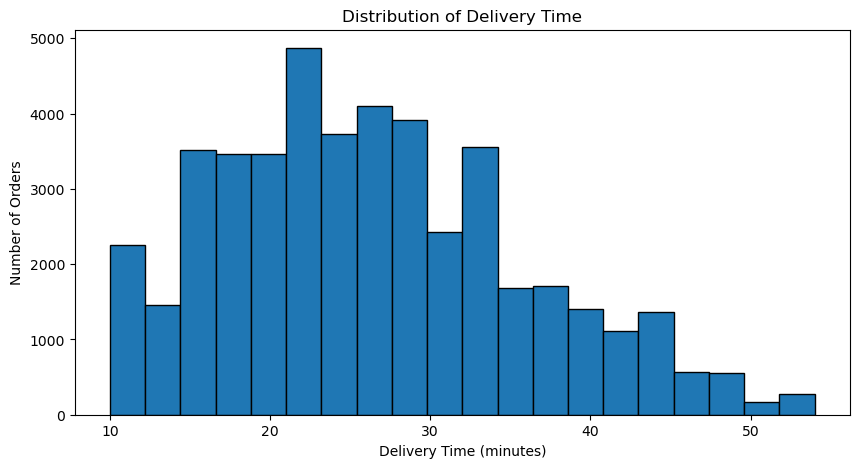

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(delivery_time, bins=20, edgecolor="black")

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of Orders")

plt.show()

In [30]:
print("متوسط وقت التوصيل:", delivery_time.mean())
print("الوسيط:", delivery_time.median())
print("أكثر وقت تكرارًا:", delivery_time.mode()[0])
print("أقل وقت:", delivery_time.min())
print("أعلى وقت:", delivery_time.max())

متوسط وقت التوصيل: 26.29460662821047
الوسيط: 26.0
أكثر وقت تكرارًا: 26
أقل وقت: 10
أعلى وقت: 54


**الاستنتاج:**

أظهرت النتائج أن متوسط وقت التوصيل يبلغ 26.29 دقيقة، والوسيط والمنوال يساويان 26 دقيقة. وتتراوح مدة التوصيل بين 10 و54 دقيقة.

يشير تقارب المتوسط والوسيط والمنوال إلى تمركز أوقات التوصيل حول 26 دقيقة، مع وجود اختلاف واضح في مدة وصول الطلبات، مما يستدعي دراسة العوامل المؤثرة في التأخير.

### 5.2 العلاقة بين الازدحام المروري ووقت التوصيل

أحلل العلاقة بين كثافة الازدحام المروري ووقت التوصيل لمعرفة ما إذا كانت الطلبات تستغرق وقتًا أطول في حالات الازدحام الشديد.

In [31]:
traffic_time = df.assign(
    Delivery_Time=delivery_time
).groupby("Road_traffic_density")["Delivery_Time"].mean()

print(traffic_time)

Road_traffic_density
High       27.240000
Jam        31.176624
Low        21.266977
Medium     26.699644
NaN        26.542429
Name: Delivery_Time, dtype: float64


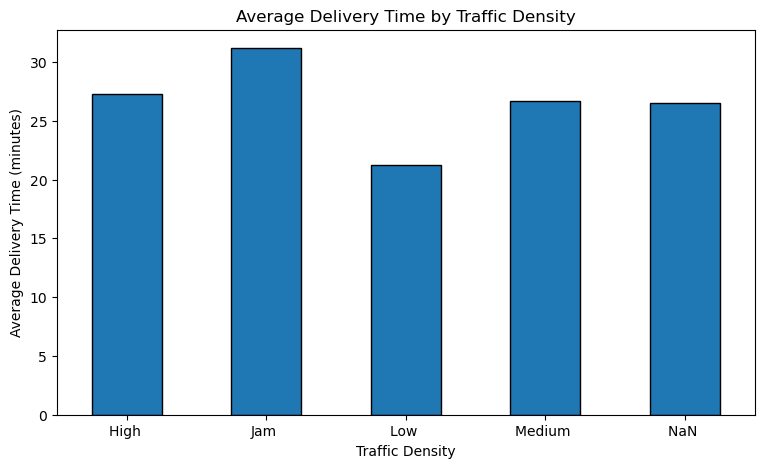

In [32]:
traffic_time.drop("NaN", errors="ignore").plot(
    kind="bar",
    figsize=(9, 5),
    edgecolor="black"
)

plt.title("Average Delivery Time by Traffic Density")
plt.xlabel("Traffic Density")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=0)
plt.show()

**الاستنتاج:**

أظهرت النتائج وجود علاقة بين مستوى الازدحام المروري ومتوسط وقت التوصيل. فقد بلغ متوسط التوصيل في الازدحام الشديد (Jam) حوالي 31.18 دقيقة، مقارنة بحوالي 21.27 دقيقة في الازدحام المنخفض (Low).

يشير ذلك إلى أن الطلبات أثناء الازدحام الشديد تستغرق وقتًا أطول في المتوسط، مما يجعل كثافة المرور عاملًا مهمًا يستحق أخذه في الاعتبار عند بناء نموذج التنبؤ بوقت التوصيل.  

### 5.3 العلاقة بين حالة الطقس ووقت التوصيل

أحلل العلاقة بين حالة الطقس ووقت التوصيل لمعرفة ما إذا كانت الظروف الجوية المختلفة مرتبطة باختلاف مدة وصول الطلبات.

In [33]:
weather_time = df.assign(
    Delivery_Time=delivery_time,
    Weather=df["Weatherconditions"].str.replace(
        "conditions ", "", regex=False
    ).str.strip()
).groupby("Weather")["Delivery_Time"].mean()

print(weather_time)

Weather
Cloudy        28.917330
Fog           28.916122
NaN           26.545455
Sandstorms    25.875517
Stormy        25.870815
Sunny         21.856947
Windy         26.118836
Name: Delivery_Time, dtype: float64


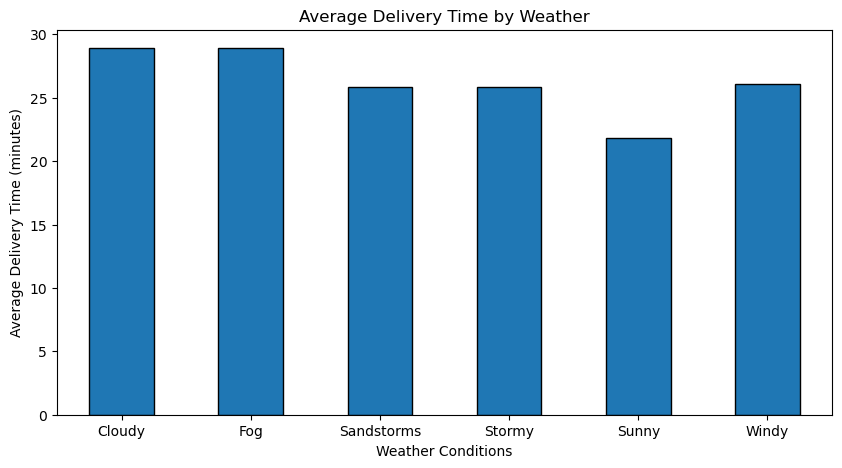

In [34]:
weather_time.drop("NaN", errors="ignore").plot(
    kind="bar",
    figsize=(10, 5),
    edgecolor="black"
)

plt.title("Average Delivery Time by Weather")
plt.xlabel("Weather Conditions")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=0)
plt.show()

**الاستنتاج:**

أظهرت النتائج اختلاف متوسط وقت التوصيل حسب حالة الطقس؛ فقد سجل الطقس الغائم أعلى متوسط بحوالي 28.92 دقيقة، يليه الضباب بحوالي 28.92 دقيقة، بينما سجل الطقس المشمس أقل متوسط بحوالي 21.86 دقيقة.

يوضح ذلك أن حالة الطقس قد تكون مرتبطة بمدة التوصيل، ولذلك من المهم تضمينها ضمن الخصائص المستخدمة في نموذج التنبؤ، مع مراعاة أن هذه النتائج توضح علاقة إحصائية ولا تثبت أن الطقس هو السبب المباشر للتأخير.   

## 6. تنظيف البيانات (Data Cleaning)   

In [35]:
import pandas as pd

# تحميل البيانات الأصلية
df = pd.read_csv("data/raw.csv")

print("حجم البيانات:", df.shape)
print(df.head())

حجم البيانات: (45593, 20)
        ID Delivery_person_ID Delivery_person_Age Delivery_person_Ratings  \
0  0x4607     INDORES13DEL02                   37                     4.9   
1  0xb379     BANGRES18DEL02                   34                     4.5   
2  0x5d6d     BANGRES19DEL01                   23                     4.4   
3  0x7a6a    COIMBRES13DEL02                   38                     4.7   
4  0x70a2     CHENRES12DEL01                   32                     4.6   

   Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  \
0            22.745049             75.892471                   22.765049   
1            12.913041             77.683237                   13.043041   
2            12.914264             77.678400                   12.924264   
3            11.003669             76.976494                   11.053669   
4            12.972793             80.249982                   13.012793   

   Delivery_location_longitude  Order_Date Time_Orderd

In [36]:
# إنشاء نسخة مستقلة من البيانات الأصلية
df_clean = df.copy()

# إزالة المسافات الزائدة من الأعمدة النصية
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# التحقق من النتيجة
print("حجم البيانات:", df_clean.shape)
print("عدد القيم المفقودة:", df_clean.isnull().sum().sum())

حجم البيانات: (45593, 20)
عدد القيم المفقودة: 0


In [37]:
# البحث عن القيم النصية التي تمثل بيانات مفقودة
missing_text = ["NaN", "nan", "None", ""]

for col in df_clean.select_dtypes(include="object").columns:
    count = df_clean[col].isin(missing_text).sum()
    if count > 0:
        print(col, ":", count)

Delivery_person_Age : 1854
Delivery_person_Ratings : 1908
Time_Orderd : 1731
Road_traffic_density : 601
multiple_deliveries : 993
Festival : 228
City : 1200


In [38]:
# تحويل النصوص التي تمثل قيماً مفقودة إلى NaN حقيقي
df_clean = df_clean.replace(
    ["NaN", "nan", "None", ""],
    pd.NA
)

# حساب القيم المفقودة بعد المعالجة
print("عدد القيم المفقودة:", df_clean.isnull().sum().sum())

# عرض عدد القيم المفقودة في كل عمود
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

عدد القيم المفقودة: 8515
Delivery_person_Age        1854
Delivery_person_Ratings    1908
Time_Orderd                1731
Road_traffic_density        601
multiple_deliveries         993
Festival                    228
City                       1200
dtype: int64


In [39]:
# تحديد الأعمدة التي نريد فحصها لأنها تحتوي على قيم مفقودة
columns_to_check = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Time_Orderd",
    "Road_traffic_density",
    "multiple_deliveries",
    "Festival",
    "City"
]

# المرور على كل عمود في القائمة وفحصه
for col in columns_to_check:

    # طباعة اسم العمود حتى نعرف النتائج تخص أي عمود
    print("\nالعمود:", col)

    # عرض نوع البيانات: نصية أو رقمية
    print("نوع البيانات:", df_clean[col].dtype)

    # عرض أكثر 10 قيم تكراراً في العمود
    print("أكثر القيم تكراراً:")
    print(df_clean[col].value_counts().head(10))


العمود: Delivery_person_Age
نوع البيانات: object
أكثر القيم تكراراً:
Delivery_person_Age
35    2262
36    2260
37    2227
30    2226
38    2219
24    2210
32    2202
22    2196
29    2191
33    2187
Name: count, dtype: int64

العمود: Delivery_person_Ratings
نوع البيانات: object
أكثر القيم تكراراً:
Delivery_person_Ratings
4.8    7148
4.7    7142
4.9    7041
4.6    6940
5      3996
4.5    3303
4.1    1430
4.2    1418
4.3    1409
4.4    1361
Name: count, dtype: int64

العمود: Time_Orderd
نوع البيانات: object
أكثر القيم تكراراً:
Time_Orderd
21:55:00    461
17:55:00    456
20:00:00    449
22:20:00    448
21:35:00    446
19:50:00    444
21:15:00    442
21:20:00    438
22:45:00    438
18:35:00    436
Name: count, dtype: int64

العمود: Road_traffic_density
نوع البيانات: object
أكثر القيم تكراراً:
Road_traffic_density
Low       15477
Jam       14143
Medium    10947
High       4425
Name: count, dtype: int64

العمود: multiple_deliveries
نوع البيانات: object
أكثر القيم تكراراً:
multiple_deliverie

In [40]:
# عرض توزيع الأعمار والتقييمات بالكامل
for col in ["Delivery_person_Age", "Delivery_person_Ratings"]:

    # طباعة اسم العمود
    print("\nالعمود:", col)

    # عرض جميع القيم وعدد تكرار كل قيمة
    print(df_clean[col].value_counts().sort_index().to_string())

    # عرض عدد القيم المفقودة
    print("عدد القيم المفقودة:", df_clean[col].isna().sum())


العمود: Delivery_person_Age
Delivery_person_Age
15      38
20    2136
21    2153
22    2196
23    2087
24    2210
25    2174
26    2159
27    2150
28    2179
29    2191
30    2226
31    2120
32    2202
33    2187
34    2166
35    2262
36    2260
37    2227
38    2219
39    2144
50      53
عدد القيم المفقودة: 1854

العمود: Delivery_person_Ratings
Delivery_person_Ratings
1        38
2.5      20
2.6      22
2.7      22
2.8      19
2.9      19
3         6
3.1      29
3.2      29
3.3      25
3.4      32
3.5     249
3.6     207
3.7     225
3.8     228
3.9     197
4      1077
4.1    1430
4.2    1418
4.3    1409
4.4    1361
4.5    3303
4.6    6940
4.7    7142
4.8    7148
4.9    7041
5      3996
6        53
عدد القيم المفقودة: 1908


In [41]:
# تحويل عمود العمر إلى أرقام، وأي قيمة غير قابلة للتحويل تصبح مفقودة
df_clean["Delivery_person_Age"] = pd.to_numeric(
    df_clean["Delivery_person_Age"], errors="coerce"
)

# تحويل عمود التقييم إلى أرقام بالطريقة نفسها
df_clean["Delivery_person_Ratings"] = pd.to_numeric(
    df_clean["Delivery_person_Ratings"], errors="coerce"
)

# عرض أقل وأعلى عمر للتأكد من نطاق الأعمار
print("أقل عمر:", df_clean["Delivery_person_Age"].min())
print("أعلى عمر:", df_clean["Delivery_person_Age"].max())

# عرض أقل وأعلى تقييم
print("أقل تقييم:", df_clean["Delivery_person_Ratings"].min())
print("أعلى تقييم:", df_clean["Delivery_person_Ratings"].max())

# عرض عدد التقييمات التي تتجاوز 5 لأنها خارج المقياس المتوقع
print(
    "التقييمات الأكبر من 5:",
    (df_clean["Delivery_person_Ratings"] > 5).sum()
)

# عرض عدد القيم المفقودة بعد التحويل
print("الأعمار المفقودة:", df_clean["Delivery_person_Age"].isna().sum())
print("التقييمات المفقودة:", df_clean["Delivery_person_Ratings"].isna().sum())

أقل عمر: 15.0
أعلى عمر: 50.0
أقل تقييم: 1.0
أعلى تقييم: 6.0
التقييمات الأكبر من 5: 53
الأعمار المفقودة: 1854
التقييمات المفقودة: 1908


In [42]:
# تحويل التقييمات الأكبر من 5 إلى قيم مفقودة لأنها خارج المقياس المتوقع
df_clean.loc[
    df_clean["Delivery_person_Ratings"] > 5,
    "Delivery_person_Ratings"
] = pd.NA

# حساب وسيط التقييمات الصحيحة لاستخدامه لاحقًا في التعويض
ratings_median = df_clean["Delivery_person_Ratings"].median()

# حساب وسيط العمر لمعرفة القيمة المناسبة للتعويض لاحقًا
age_median = df_clean["Delivery_person_Age"].median()

# عرض الوسيطين وعدد القيم المفقودة بعد التصحيح
print("وسيط العمر:", age_median)
print("وسيط التقييم:", ratings_median)
print("التقييمات المفقودة بعد التصحيح:", df_clean["Delivery_person_Ratings"].isna().sum())

وسيط العمر: 30.0
وسيط التقييم: 4.7
التقييمات المفقودة بعد التصحيح: 1961


In [43]:
# تحويل عدد الطلبات المتعددة إلى أرقام
df_clean["multiple_deliveries"] = pd.to_numeric(
    df_clean["multiple_deliveries"], errors="coerce"
)

# عرض عدد مرات تكرار كل قيمة
print("توزيع عدد الطلبات المتعددة:")
print(df_clean["multiple_deliveries"].value_counts(dropna=False).sort_index())

# عرض أقل وأعلى قيمة
print("أقل قيمة:", df_clean["multiple_deliveries"].min())
print("أعلى قيمة:", df_clean["multiple_deliveries"].max())

# حساب الوسيط والمنوال لاختيار طريقة التعويض المناسبة لاحقًا
print("الوسيط:", df_clean["multiple_deliveries"].median())
print("المنوال:", df_clean["multiple_deliveries"].mode()[0])

# عرض عدد القيم المفقودة
print("القيم المفقودة:", df_clean["multiple_deliveries"].isna().sum())

توزيع عدد الطلبات المتعددة:
multiple_deliveries
0.0    14095
1.0    28159
2.0     1985
3.0      361
NaN      993
Name: count, dtype: int64
أقل قيمة: 0.0
أعلى قيمة: 3.0
الوسيط: 1.0
المنوال: 1.0
القيم المفقودة: 993


In [44]:

# تحديد الأعمدة النصية التي نحتاج إلى فحصها
categorical_columns = [
    "Time_Orderd",
    "Road_traffic_density",
    "Festival",
    "City"
]

# المرور على كل عمود لفحص القيم الموجودة فيه
for col in categorical_columns:

    # طباعة اسم العمود
    print("\nالعمود:", col)

    # عرض جميع القيم وعدد مرات تكرارها، بما فيها القيم المفقودة
    print(df_clean[col].value_counts(dropna=False).to_string())

    # حساب عدد القيم المفقودة في العمود
    print("عدد القيم المفقودة:", df_clean[col].isna().sum())



العمود: Time_Orderd
Time_Orderd
<NA>        1731
21:55:00     461
17:55:00     456
20:00:00     449
22:20:00     448
21:35:00     446
19:50:00     444
21:15:00     442
22:45:00     438
21:20:00     438
19:55:00     436
18:35:00     436
21:25:00     435
17:35:00     435
18:10:00     435
22:10:00     434
23:30:00     434
17:25:00     432
17:40:00     431
00:00:00     430
21:40:00     429
23:25:00     429
22:35:00     428
18:20:00     425
22:50:00     425
19:00:00     424
17:15:00     424
21:10:00     423
20:40:00     423
20:45:00     423
23:00:00     422
23:35:00     422
17:45:00     421
18:30:00     421
20:50:00     420
19:25:00     420
19:30:00     419
23:40:00     419
20:35:00     416
19:40:00     416
20:20:00     416
17:20:00     414
23:10:00     414
19:15:00     414
21:45:00     413
19:35:00     412
17:10:00     412
20:30:00     412
23:55:00     411
18:40:00     411
17:50:00     410
22:30:00     410
21:00:00     409
19:10:00     407
20:15:00     405
23:45:00     405
22:40:00     40

In [45]:
# فحص كثافة حركة المرور
print("=== كثافة حركة المرور ===")
print(df_clean["Road_traffic_density"].value_counts(dropna=False).to_string())

# فحص وجود المهرجان
print("\n=== المهرجان ===")
print(df_clean["Festival"].value_counts(dropna=False).to_string())

# فحص المدن
print("\n=== المدن ===")
print(df_clean["City"].value_counts(dropna=False).to_string())

# عرض عدد الأوقات المختلفة للطلب
print("\n=== أوقات الطلب ===")
print("عدد الأوقات المختلفة:", df_clean["Time_Orderd"].nunique())
print("أكثر 10 أوقات تكرارًا:")
print(df_clean["Time_Orderd"].value_counts().head(10).to_string())

=== كثافة حركة المرور ===
Road_traffic_density
Low       15477
Jam       14143
Medium    10947
High       4425
<NA>        601

=== المهرجان ===
Festival
No      44469
Yes       896
<NA>      228

=== المدن ===
City
Metropolitian    34093
Urban            10136
<NA>              1200
Semi-Urban         164

=== أوقات الطلب ===
عدد الأوقات المختلفة: 176
أكثر 10 أوقات تكرارًا:
Time_Orderd
21:55:00    461
17:55:00    456
20:00:00    449
22:20:00    448
21:35:00    446
19:50:00    444
21:15:00    442
21:20:00    438
22:45:00    438
18:35:00    436


### قرارات معالجة القيم المفقودة

قررت الاحتفاظ بالسجلات التي تحتوي على قيم مفقودة في الأعمدة النصية، واستبدال القيم المفقودة بالفئة `Unknown` بدلًا من حذف السجلات أو تخمين قيم غير مؤكدة.

- **وقت الطلب (Time_Orderd):** كان يحتوي على 1,731 قيمة مفقودة، وتم الاحتفاظ بها تحت فئة `Unknown`؛ لأن العمود يحتوي على 176 وقتًا مختلفًا، وتعويضها بوقت واحد قد يؤثر على توزيع البيانات.
- **كثافة حركة المرور (Road_traffic_density):** كان يحتوي على 601 قيمة مفقودة، وتم استخدام `Unknown` بدلًا من افتراض حالة المرور.
- **المهرجان (Festival):** كان يحتوي على 228 قيمة مفقودة، وتم استخدام `Unknown` بدلًا من افتراض أن عدم وجود قيمة يعني عدم وجود مهرجان.
- **المدينة (City):** كان يحتوي على 1,200 قيمة مفقودة، وتم استخدام `Unknown` حتى لا ننسب الطلب إلى مدينة غير مؤكدة.

**سبب القرار:** المحافظة على جميع السجلات وتجنب إدخال معلومات غير مؤكدة في البيانات.  

In [46]:
# تحديد الأعمدة النصية التي سنحتفظ بقيمها المفقودة كفئة مستقلة
categorical_columns = [
    "Time_Orderd",
    "Road_traffic_density",
    "Festival",
    "City"
]

# استبدال القيم المفقودة بكلمة Unknown بدل حذف السجلات أو تخمين القيم
for col in categorical_columns:
    df_clean[col] = df_clean[col].fillna("Unknown")

# التحقق من عدد القيم المفقودة بعد المعالجة
print("إجمالي القيم المفقودة في الأعمدة الأربعة:")
print(df_clean[categorical_columns].isna().sum().sum())

# التأكد من عدد السجلات التي أصبحت ضمن فئة Unknown
for col in categorical_columns:
    print(col, ":", (df_clean[col] == "Unknown").sum())

إجمالي القيم المفقودة في الأعمدة الأربعة:
0
Time_Orderd : 1731
Road_traffic_density : 601
Festival : 228
City : 1200


In [47]:
# تعويض الأعمار المفقودة بالوسيط الذي حسبناه سابقًا وهو 30
df_clean["Delivery_person_Age"] = df_clean["Delivery_person_Age"].fillna(age_median)

# تعويض التقييمات المفقودة بالوسيط الذي حسبناه سابقًا وهو 4.7
df_clean["Delivery_person_Ratings"] = df_clean["Delivery_person_Ratings"].fillna(ratings_median)

# تعويض عدد الطلبات المتعددة بالمنوال الذي حسبناه سابقًا وهو 1
df_clean["multiple_deliveries"] = df_clean["multiple_deliveries"].fillna(1)

# التحقق من عدد القيم المفقودة في الأعمدة الرقمية الثلاثة
for col in ["Delivery_person_Age", "Delivery_person_Ratings", "multiple_deliveries"]:
    print(col, ":", df_clean[col].isna().sum())

Delivery_person_Age : 0
Delivery_person_Ratings : 0
multiple_deliveries : 0


### معالجة القيم المفقودة في الأعمدة الرقمية

اتخذت القرارات التالية لمعالجة القيم المفقودة:

- **Delivery_person_Age:** عوّضت 1,854 قيمة مفقودة بالوسيط 30؛ لأنه أقل تأثرًا بالقيم المتطرفة.
- **Delivery_person_Ratings:** حوّلت 53 تقييمًا أكبر من 5 إلى قيم مفقودة، ثم عوّضت إجمالي 1,961 قيمة بالوسيط 4.7؛ لأن مقياس التقييم المتوقع من 1 إلى 5.
- **multiple_deliveries:** عوّضت 993 قيمة مفقودة بالمنوال 1؛ لأنه الأكثر تكرارًا ويمثل عدد الطلبات الإضافية.

**النتيجة:** أصبحت القيم المفقودة في الأعمدة الرقمية الثلاثة تساوي صفرًا، مع المحافظة على جميع السجلات.  

In [48]:
# عرض القيم الموجودة في عمود الطقس قبل التنظيف لمعرفة شكل البيانات
print("القيم قبل التنظيف:")
print(df_clean["Weatherconditions"].value_counts(dropna=False).head(10))

# إزالة كلمة conditions من أسماء حالات الطقس لتوحيد تنسيق القيم
df_clean["Weatherconditions"] = (
    df_clean["Weatherconditions"]
    .str.replace("conditions", "", regex=False)
    .str.strip()  # إزالة المسافات الزائدة من بداية ونهاية النص
)

# تحويل القيم المفقودة المكتوبة كنص إلى قيم مفقودة حقيقية
df_clean["Weatherconditions"] = df_clean["Weatherconditions"].replace(
    ["NaN", "nan", "None", ""],
    pd.NA
)

# عرض حالات الطقس بعد التنظيف للتأكد من توحيد الأسماء
print("\nالقيم بعد التنظيف:")
print(df_clean["Weatherconditions"].value_counts(dropna=False))

# حساب عدد القيم المفقودة في عمود الطقس بعد التنظيف
print("\nعدد القيم المفقودة:", df_clean["Weatherconditions"].isna().sum())

القيم قبل التنظيف:
Weatherconditions
conditions Fog           7654
conditions Stormy        7586
conditions Cloudy        7536
conditions Sandstorms    7495
conditions Windy         7422
conditions Sunny         7284
conditions NaN            616
Name: count, dtype: int64

القيم بعد التنظيف:
Weatherconditions
Fog           7654
Stormy        7586
Cloudy        7536
Sandstorms    7495
Windy         7422
Sunny         7284
<NA>           616
Name: count, dtype: int64

عدد القيم المفقودة: 616


In [49]:
# تعويض القيم المفقودة في عمود الطقس بفئة Unknown
df_clean["Weatherconditions"] = df_clean["Weatherconditions"].fillna("Unknown")

# عرض توزيع حالات الطقس بعد معالجة القيم المفقودة
print("توزيع حالات الطقس بعد التنظيف:")
print(df_clean["Weatherconditions"].value_counts())

# التحقق من عدم وجود قيم مفقودة في عمود الطقس
print("\nعدد القيم المفقودة:")
print(df_clean["Weatherconditions"].isna().sum())

توزيع حالات الطقس بعد التنظيف:
Weatherconditions
Fog           7654
Stormy        7586
Cloudy        7536
Sandstorms    7495
Windy         7422
Sunny         7284
Unknown        616
Name: count, dtype: int64

عدد القيم المفقودة:
0


In [50]:
# تحديد أعمدة إحداثيات المطعم والعميل
coordinate_columns = [
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

# عرض عدد الإحداثيات التي تساوي صفرًا في كل عمود
print("عدد الإحداثيات الصفرية في كل عمود:")
for col in coordinate_columns:
    print(col, ":", (df_clean[col] == 0).sum())

# حساب عدد السجلات التي تحتوي على إحداثيات صفرية في أي موقع
zero_coordinates = (
    (df_clean[coordinate_columns] == 0).any(axis=1)
)

print("\nعدد السجلات التي تحتوي على إحداثيات صفرية:")
print(zero_coordinates.sum())

# عرض أمثلة من السجلات التي تحتوي على إحداثيات صفرية لفحصها
print("\nأمثلة على الإحداثيات الصفرية:")
print(df_clean.loc[zero_coordinates, coordinate_columns].head(10))

عدد الإحداثيات الصفرية في كل عمود:
Restaurant_latitude : 3640
Restaurant_longitude : 3640
Delivery_location_latitude : 0
Delivery_location_longitude : 0

عدد السجلات التي تحتوي على إحداثيات صفرية:
3640

أمثلة على الإحداثيات الصفرية:
    Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  \
33                  0.0                   0.0                        0.11   
52                  0.0                   0.0                        0.03   
57                  0.0                   0.0                        0.08   
59                  0.0                   0.0                        0.06   
67                  0.0                   0.0                        0.02   
68                  0.0                   0.0                        0.04   
72                  0.0                   0.0                        0.08   
73                  0.0                   0.0                        0.02   
76                  0.0                   0.0                        0.05 

In [51]:
# تحديد أعمدة إحداثيات المطعم والعميل
coordinate_columns = [
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

# عرض أقل وأعلى قيمة في كل عمود لفحص نطاق الإحداثيات
for col in coordinate_columns:
    print("\nالعمود:", col)
    print("أقل قيمة:", df_clean[col].min())
    print("أعلى قيمة:", df_clean[col].max())

# حساب عدد الإحداثيات السالبة في كل عمود
print("\nعدد الإحداثيات السالبة:")
for col in coordinate_columns:
    print(col, ":", (df_clean[col] < 0).sum())


العمود: Restaurant_latitude
أقل قيمة: -30.905562
أعلى قيمة: 30.914057

العمود: Restaurant_longitude
أقل قيمة: -88.366217
أعلى قيمة: 88.433452

العمود: Delivery_location_latitude
أقل قيمة: 0.01
أعلى قيمة: 31.054057

العمود: Delivery_location_longitude
أقل قيمة: 0.01
أعلى قيمة: 88.563452

عدد الإحداثيات السالبة:
Restaurant_latitude : 431
Restaurant_longitude : 162
Delivery_location_latitude : 0
Delivery_location_longitude : 0


In [52]:
# تحديد السجلات التي تحتوي على إحداثيات سالبة للمطعم
negative_coordinates = (
    (df_clean["Restaurant_latitude"] < 0) |
    (df_clean["Restaurant_longitude"] < 0)
)

# تحديد السجلات التي تحتوي على إحداثيات صفرية للمطعم
zero_coordinates = (
    (df_clean["Restaurant_latitude"] == 0) |
    (df_clean["Restaurant_longitude"] == 0)
)

# حساب عدد السجلات التي تحتوي على إحداثيات سالبة
print("السجلات ذات الإحداثيات السالبة:")
print(negative_coordinates.sum())

# حساب عدد السجلات التي تحتوي على إحداثيات صفرية
print("\nالسجلات ذات الإحداثيات الصفرية:")
print(zero_coordinates.sum())

# حساب عدد السجلات المتأثرة بأي من المشكلتين دون تكرار
affected_coordinates = negative_coordinates | zero_coordinates
print("\nإجمالي السجلات المتأثرة دون تكرار:")
print(affected_coordinates.sum())

# عرض أمثلة من الإحداثيات السالبة لفحصها
print("\nأمثلة على الإحداثيات السالبة:")
print(
    df_clean.loc[
        negative_coordinates,
        ["Restaurant_latitude", "Restaurant_longitude"]
    ].head(10)
)

السجلات ذات الإحداثيات السالبة:
431

السجلات ذات الإحداثيات الصفرية:
3640

إجمالي السجلات المتأثرة دون تكرار:
4071

أمثلة على الإحداثيات السالبة:
      Restaurant_latitude  Restaurant_longitude
92             -27.163303             78.057044
283            -27.165108             78.015053
289            -18.551440            -73.804855
425            -30.366322            -78.070453
534            -12.325461            -76.632278
583            -12.316967             76.603067
762            -23.359194            -85.325447
1059           -26.477750            -80.351569
1091           -15.546594             73.760431
1157           -12.337978             76.616792


In [53]:
# تحديد أعمدة إحداثيات المطعم التي نحتاج إلى تنظيفها
restaurant_coordinates = [
    "Restaurant_latitude",
    "Restaurant_longitude"
]

# تحديد السجلات التي تحتوي على إحداثيات صفرية أو سالبة
# اعتبرناها غير صالحة لأن مواقع المطاعم في هذا المشروع تقع في الهند
invalid_coordinates = (
    (df_clean["Restaurant_latitude"] <= 0) |
    (df_clean["Restaurant_longitude"] <= 0)
)

# تحويل الإحداثيات غير الصالحة إلى قيم مفقودة NaN
# مع الاحتفاظ ببقية بيانات الطلب وعدم حذف أي سجل
df_clean.loc[invalid_coordinates, restaurant_coordinates] = float("nan")

# حساب عدد السجلات التي أصبحت إحداثيات المطعم فيها مفقودة
print("عدد السجلات ذات إحداثيات المطعم المفقودة:")
print(df_clean[restaurant_coordinates].isna().any(axis=1).sum())

# التأكد من عدم بقاء إحداثيات صفرية أو سالبة
for col in restaurant_coordinates:

    # عرض اسم العمود
    print("\nالعمود:", col)

    # التحقق من عدد القيم الصفرية
    print("القيم الصفرية:", (df_clean[col] == 0).sum())

    # التحقق من عدد القيم السالبة
    print("القيم السالبة:", (df_clean[col] < 0).sum())

    # التحقق من عدد القيم المفقودة
    print("القيم المفقودة:", df_clean[col].isna().sum())

عدد السجلات ذات إحداثيات المطعم المفقودة:
4071

العمود: Restaurant_latitude
القيم الصفرية: 0
القيم السالبة: 0
القيم المفقودة: 4071

العمود: Restaurant_longitude
القيم الصفرية: 0
القيم السالبة: 0
القيم المفقودة: 4071


### معالجة الإحداثيات غير الصالحة

أثناء فحص إحداثيات المطاعم والعملاء، اكتشفت وجود إحداثيات صفرية وسالبة في بيانات المطاعم.

- وُجدت 3,640 حالة تحتوي على إحداثيات صفرية.
- وُجدت 431 حالة تحتوي على إحداثيات سالبة.
- بلغ إجمالي السجلات المتأثرة دون تكرار 4,071 سجلًا، أي حوالي 8.93% من البيانات.

قررت تحويل إحداثيات المطاعم غير الصالحة إلى قيم مفقودة `NaN`، مع الاحتفاظ ببقية بيانات الطلب وعدم حذف السجلات.

**سبب القرار:** الإحداثيات غير الصالحة قد تؤدي إلى حساب مسافات غير دقيقة بين المطعم والعميل، لذلك فضّلت الاحتفاظ بالطلبات وعدم استخدام مواقع غير موثوقة.  

In [54]:
# إزالة النص (min) والمسافات من قيم وقت التوصيل
df_clean["Time_taken(min)"] = (
    df_clean["Time_taken(min)"]
    .str.replace("(min)", "", regex=False)
    .str.strip()
)

# تحويل وقت التوصيل من نص إلى أرقام
df_clean["Time_taken(min)"] = pd.to_numeric(
    df_clean["Time_taken(min)"],
    errors="coerce"
)

# عرض نوع البيانات بعد التحويل
print("نوع البيانات:", df_clean["Time_taken(min)"].dtype)

# عرض عدد القيم التي لم تتحول إلى أرقام
print("عدد القيم المفقودة:", df_clean["Time_taken(min)"].isna().sum())

# عرض إحصائيات وقت التوصيل
print("\nإحصائيات وقت التوصيل:")
print(df_clean["Time_taken(min)"].describe())

# عرض أول خمس قيم بعد التنظيف
print("\nأول خمس قيم:")
print(df_clean["Time_taken(min)"].head())

نوع البيانات: int64
عدد القيم المفقودة: 0

إحصائيات وقت التوصيل:
count    45593.000000
mean        26.294607
std          9.383806
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: Time_taken(min), dtype: float64

أول خمس قيم:
0    24
1    33
2    26
3    21
4    30
Name: Time_taken(min), dtype: int64


In [55]:
# تحديد الأعمدة التي يجب أن تكون رقمية
numeric_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "multiple_deliveries",
    "Vehicle_condition"
]

# تحويل الأعمدة إلى أنواع رقمية
for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# عرض أنواع البيانات بعد التحويل
print("أنواع البيانات بعد التحويل:")
print(df_clean[numeric_columns].dtypes)

# عرض عدد القيم المفقودة في كل عمود
print("\nالقيم المفقودة:")
print(df_clean[numeric_columns].isna().sum())

أنواع البيانات بعد التحويل:
Delivery_person_Age        float64
Delivery_person_Ratings    float64
multiple_deliveries        float64
Vehicle_condition            int64
dtype: object

القيم المفقودة:
Delivery_person_Age        0
Delivery_person_Ratings    0
multiple_deliveries        0
Vehicle_condition          0
dtype: int64


In [56]:
# تحويل عمود تاريخ الطلب إلى نوع تاريخ
# تنسيق التاريخ في البيانات هو يوم-شهر-سنة
df_clean["Order_Date"] = pd.to_datetime(
    df_clean["Order_Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# عرض نوع البيانات بعد التحويل
print("نوع البيانات:", df_clean["Order_Date"].dtype)

# التحقق من عدد التواريخ المفقودة
print("عدد التواريخ المفقودة:", df_clean["Order_Date"].isna().sum())

# عرض أول خمسة تواريخ
print("\nأول خمسة تواريخ:")
print(df_clean["Order_Date"].head())

# عرض أقدم وأحدث تاريخ
print("\nأقدم تاريخ:", df_clean["Order_Date"].min())
print("أحدث تاريخ:", df_clean["Order_Date"].max())

نوع البيانات: datetime64[ns]
عدد التواريخ المفقودة: 0

أول خمسة تواريخ:
0   2022-03-19
1   2022-03-25
2   2022-03-19
3   2022-04-05
4   2022-03-26
Name: Order_Date, dtype: datetime64[ns]

أقدم تاريخ: 2022-02-11 00:00:00
أحدث تاريخ: 2022-04-06 00:00:00


In [57]:
# تحديد أعمدة أوقات الطلب والاستلام
time_columns = [
    "Time_Orderd",
    "Time_Order_picked"
]

# عرض نوع البيانات وعدد القيم المفقودة والقيم غير المعروفة
for col in time_columns:

    print("\n---", col, "---")

    # عرض نوع بيانات العمود
    print("نوع البيانات:", df_clean[col].dtype)

    # حساب القيم المفقودة
    print("القيم المفقودة:", df_clean[col].isna().sum())

    # حساب القيم غير المعروفة
    print("القيم غير المعروفة:", (df_clean[col] == "Unknown").sum())

    # عرض أكثر الأوقات تكرارًا
    print("\nأكثر الأوقات تكرارًا:")
    print(df_clean[col].value_counts().head())


--- Time_Orderd ---
نوع البيانات: object
القيم المفقودة: 0
القيم غير المعروفة: 1731

أكثر الأوقات تكرارًا:
Time_Orderd
Unknown     1731
21:55:00     461
17:55:00     456
20:00:00     449
22:20:00     448
Name: count, dtype: int64

--- Time_Order_picked ---
نوع البيانات: object
القيم المفقودة: 0
القيم غير المعروفة: 0

أكثر الأوقات تكرارًا:
Time_Order_picked
21:30:00    496
22:50:00    474
22:40:00    458
18:40:00    457
17:55:00    456
Name: count, dtype: int64


In [58]:
# تحديد أعمدة الوقت المراد فحصها
time_columns = [
    "Time_Orderd",
    "Time_Order_picked"
]

# فحص صيغة الوقت في كل عمود
for col in time_columns:

    print("\n--- فحص العمود:", col, "---")

    # استبعاد القيم غير المعروفة
    valid_times = df_clean.loc[
        df_clean[col] != "Unknown", col
    ]

    # محاولة تحويل الأوقات إلى صيغة وقت
    converted_times = pd.to_datetime(
        valid_times,
        format="%H:%M:%S",
        errors="coerce"
    )

    # حساب الأوقات التي لم تنجح في التحويل
    invalid_count = converted_times.isna().sum()

    print("عدد الأوقات الصحيحة:", converted_times.notna().sum())
    print("عدد الأوقات غير الصالحة:", invalid_count)

    # عرض أمثلة من الأوقات
    print("أمثلة:")
    print(valid_times.head())


--- فحص العمود: Time_Orderd ---
عدد الأوقات الصحيحة: 43862
عدد الأوقات غير الصالحة: 0
أمثلة:
0    11:30:00
1    19:45:00
2    08:30:00
3    18:00:00
4    13:30:00
Name: Time_Orderd, dtype: object

--- فحص العمود: Time_Order_picked ---
عدد الأوقات الصحيحة: 45593
عدد الأوقات غير الصالحة: 0
أمثلة:
0    11:45:00
1    19:50:00
2    08:45:00
3    18:10:00
4    13:45:00
Name: Time_Order_picked, dtype: object


In [59]:
# تحديد الأعمدة التصنيفية التي نريد مراجعتها
categorical_columns = [
    "Vehicle_condition",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City",
    "Road_traffic_density",
    "Weatherconditions"
]

# عرض القيم وعدد تكرار كل قيمة في الأعمدة
for col in categorical_columns:

    print("\n---", col, "---")

    # حساب عدد مرات ظهور كل قيمة
    print(df_clean[col].value_counts(dropna=False))

    # عرض عدد القيم المختلفة
    print("عدد القيم المختلفة:", df_clean[col].nunique())


--- Vehicle_condition ---
Vehicle_condition
2    15034
1    15030
0    15009
3      520
Name: count, dtype: int64
عدد القيم المختلفة: 4

--- Type_of_order ---
Type_of_order
Snack     11533
Meal      11458
Drinks    11322
Buffet    11280
Name: count, dtype: int64
عدد القيم المختلفة: 4

--- Type_of_vehicle ---
Type_of_vehicle
motorcycle          26435
scooter             15276
electric_scooter     3814
bicycle                68
Name: count, dtype: int64
عدد القيم المختلفة: 4

--- Festival ---
Festival
No         44469
Yes          896
Unknown      228
Name: count, dtype: int64
عدد القيم المختلفة: 3

--- City ---
City
Metropolitian    34093
Urban            10136
Unknown           1200
Semi-Urban         164
Name: count, dtype: int64
عدد القيم المختلفة: 4

--- Road_traffic_density ---
Road_traffic_density
Low        15477
Jam        14143
Medium     10947
High        4425
Unknown      601
Name: count, dtype: int64
عدد القيم المختلفة: 5

--- Weatherconditions ---
Weatherconditions
Fog    

In [60]:
# إنشاء مؤشر يوضح هل إحداثيات المطعم مفقودة
# القيمة 1 تعني أن الإحداثيات غير متوفرة
# القيمة 0 تعني أن الإحداثيات متوفرة
df_clean["Restaurant_coordinates_missing"] = (
    df_clean["Restaurant_latitude"].isna() |
    df_clean["Restaurant_longitude"].isna()
).astype(int)

# عرض عدد السجلات حسب حالة الإحداثيات
print("حالة إحداثيات المطعم:")
print(df_clean["Restaurant_coordinates_missing"].value_counts())

# حساب نسبة السجلات التي تفتقد إحداثيات المطعم
print(
    "\nنسبة الإحداثيات المفقودة:",
    round(df_clean["Restaurant_coordinates_missing"].mean() * 100, 2),
    "%"
)

حالة إحداثيات المطعم:
Restaurant_coordinates_missing
0    41522
1     4071
Name: count, dtype: int64

نسبة الإحداثيات المفقودة: 8.93 %


In [61]:
# عرض حجم البيانات بعد التنظيف
print("حجم البيانات النهائي:", df_clean.shape)

# حساب القيم المفقودة في كل عمود
print("\nالقيم المفقودة في الأعمدة:")
print(df_clean.isna().sum())

# حساب إجمالي القيم المفقودة
print("\nإجمالي القيم المفقودة:")
print(df_clean.isna().sum().sum())

# عرض أنواع البيانات بعد التنظيف
print("\nأنواع البيانات:")
print(df_clean.dtypes)

# التأكد من عدم وجود صفوف مكررة
print("\nعدد الصفوف المكررة:")
print(df_clean.duplicated().sum())

حجم البيانات النهائي: (45593, 21)

القيم المفقودة في الأعمدة:
ID                                   0
Delivery_person_ID                   0
Delivery_person_Age                  0
Delivery_person_Ratings              0
Restaurant_latitude               4071
Restaurant_longitude              4071
Delivery_location_latitude           0
Delivery_location_longitude          0
Order_Date                           0
Time_Orderd                          0
Time_Order_picked                    0
Weatherconditions                    0
Road_traffic_density                 0
Vehicle_condition                    0
Type_of_order                        0
Type_of_vehicle                      0
multiple_deliveries                  0
Festival                             0
City                                 0
Time_taken(min)                      0
Restaurant_coordinates_missing       0
dtype: int64

إجمالي القيم المفقودة:
8142

أنواع البيانات:
ID                                        object
Delivery_pe

In [62]:
# حفظ البيانات بعد التنظيف في ملف clean.csv
df_clean.to_csv("data/clean.csv", index=False)

# التأكد من نجاح الحفظ
print("تم حفظ البيانات النظيفة بنجاح")
print("عدد الصفوف:", df_clean.shape[0])
print("عدد الأعمدة:", df_clean.shape[1])

تم حفظ البيانات النظيفة بنجاح
عدد الصفوف: 45593
عدد الأعمدة: 21


In [63]:
# استيراد مكتبة NumPy للعمليات الحسابية
import numpy as np

# استيراد مكتبة Matplotlib لرسم النتائج
import matplotlib.pyplot as plt

# التأكد من تحميل البيانات النظيفة
print("حجم البيانات:", df_clean.shape)

حجم البيانات: (45593, 21)


In [64]:
# تحويل إحداثيات المطعم والعميل من درجات إلى راديان
restaurant_lat = np.radians(df_clean["Restaurant_latitude"])
restaurant_lon = np.radians(df_clean["Restaurant_longitude"])
delivery_lat = np.radians(df_clean["Delivery_location_latitude"])
delivery_lon = np.radians(df_clean["Delivery_location_longitude"])

# حساب الفرق بين إحداثيات المطعم والعميل
lat_diff = delivery_lat - restaurant_lat
lon_diff = delivery_lon - restaurant_lon

# تطبيق معادلة Haversine لحساب المسافة
a = (
    np.sin(lat_diff / 2) ** 2
    + np.cos(restaurant_lat) * np.cos(delivery_lat)
    * np.sin(lon_diff / 2) ** 2
)

# حساب المسافة بالكيلومترات
df_clean["Distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

# عرض معلومات المسافة الجديدة
print("عدد القيم المتوفرة:", df_clean["Distance_km"].count())
print("عدد القيم المفقودة:", df_clean["Distance_km"].isna().sum())
print("متوسط المسافة:", df_clean["Distance_km"].mean())
print("أقل مسافة:", df_clean["Distance_km"].min())
print("أكبر مسافة:", df_clean["Distance_km"].max())

عدد القيم المتوفرة: 41522
عدد القيم المفقودة: 4071
متوسط المسافة: 9.72012893096176
أقل مسافة: 1.4650674052309467
أكبر مسافة: 20.969489380087342


In [65]:
# تحويل وقت تسجيل الطلب إلى صيغة الوقت
order_time = pd.to_datetime(
    df_clean["Time_Orderd"],
    format="%H:%M:%S",
    errors="coerce"
)

# تحويل وقت استلام المندوب للطلب إلى صيغة الوقت
picked_time = pd.to_datetime(
    df_clean["Time_Order_picked"],
    format="%H:%M:%S",
    errors="coerce"
)

# حساب الفرق بين وقت الاستلام ووقت تسجيل الطلب بالدقائق
prep_minutes = (
    (picked_time - order_time).dt.total_seconds() / 60
)

# معالجة الحالات التي يتجاوز فيها الوقت منتصف الليل
prep_minutes = prep_minutes.where(
    prep_minutes >= 0,
    prep_minutes + 24 * 60
)

# إضافة خاصية وقت تجهيز الطلب إلى البيانات
df_clean["Preparation_Time"] = prep_minutes

# عرض ملخص وقت التجهيز
print("عدد القيم المتوفرة:", df_clean["Preparation_Time"].count())
print("عدد القيم المفقودة:", df_clean["Preparation_Time"].isna().sum())
print("متوسط وقت التجهيز:", df_clean["Preparation_Time"].mean())
print("أقل وقت تجهيز:", df_clean["Preparation_Time"].min())
print("أكبر وقت تجهيز:", df_clean["Preparation_Time"].max())

عدد القيم المتوفرة: 43862
عدد القيم المفقودة: 1731
متوسط وقت التجهيز: 9.989398568236743
أقل وقت تجهيز: 5.0
أكبر وقت تجهيز: 15.0


In [66]:
# استخراج ساعة الطلب من عمود وقت تسجيل الطلب
order_hour = pd.to_datetime(
    df_clean["Time_Orderd"],
    format="%H:%M:%S",
    errors="coerce"
).dt.hour

# إنشاء عمود جديد لتصنيف الفترة الزمنية
df_clean["Order_Time_Period"] = "Unknown"

# تصنيف الطلبات حسب الساعة
df_clean.loc[order_hour.between(5, 11), "Order_Time_Period"] = "Morning"
df_clean.loc[order_hour.between(12, 16), "Order_Time_Period"] = "Afternoon"
df_clean.loc[order_hour.between(17, 20), "Order_Time_Period"] = "Evening"

# تصنيف الطلبات الليلية، وتشمل من 9 مساءً إلى قبل 5 صباحًا
df_clean.loc[
    (order_hour >= 21) | (order_hour < 5),
    "Order_Time_Period"
] = "Night"

# عرض عدد الطلبات في كل فترة
print("عدد الطلبات حسب الفترة الزمنية:")
print(df_clean["Order_Time_Period"].value_counts())

# عرض عدد القيم غير المعروفة
print("\nعدد الفترات غير المعروفة:")
print((df_clean["Order_Time_Period"] == "Unknown").sum())

عدد الطلبات حسب الفترة الزمنية:
Order_Time_Period
Evening      17892
Night        14203
Morning       7718
Afternoon     4049
Unknown       1731
Name: count, dtype: int64

عدد الفترات غير المعروفة:
1731


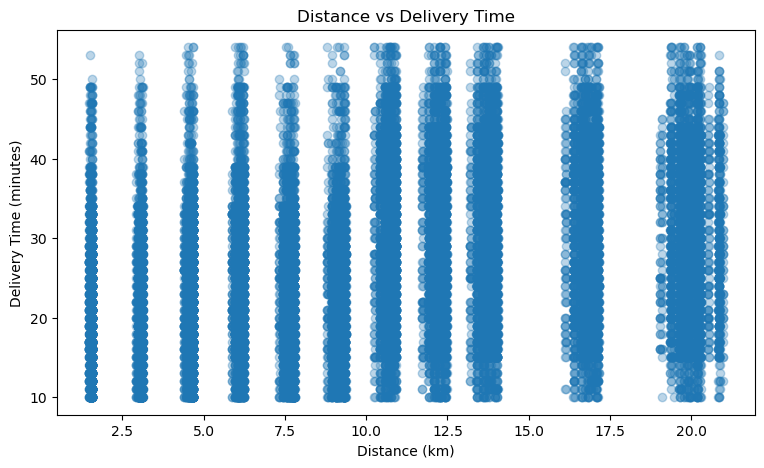

In [67]:
# إنشاء رسم يوضح العلاقة بين المسافة ووقت التوصيل
plt.figure(figsize=(9, 5))

# رسم متوسط وقت التوصيل حسب المسافة
plt.scatter(
    df_clean["Distance_km"],
    df_clean["Time_taken(min)"],
    alpha=0.3
)

# إضافة عنوان وتسميات للمحاور
plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (minutes)")

# عرض الرسم
plt.show()

In [68]:
# حساب معامل الارتباط بين المسافة ووقت التوصيل
distance_correlation = df_clean[
    ["Distance_km", "Time_taken(min)"]
].corr().iloc[0, 1]

# حساب متوسط وقت التوصيل حسب فئات المسافة
df_clean["Distance_Group"] = pd.cut(
    df_clean["Distance_km"],
    bins=[0, 5, 10, 15, 25],
    labels=["0-5 km", "5-10 km", "10-15 km", "15-25 km"]
)

# حساب متوسط وقت التوصيل لكل فئة
distance_analysis = df_clean.groupby(
    "Distance_Group",
    observed=False
)["Time_taken(min)"].mean()

# عرض النتائج
print("معامل الارتباط بين المسافة ووقت التوصيل:")
print(round(distance_correlation, 3))

print("\nمتوسط وقت التوصيل حسب المسافة:")
print(distance_analysis.round(2))

معامل الارتباط بين المسافة ووقت التوصيل:
0.321

متوسط وقت التوصيل حسب المسافة:
Distance_Group
0-5 km      22.18
5-10 km     24.39
10-15 km    29.84
15-25 km    29.87
Name: Time_taken(min), dtype: float64


**ملاحظة وتحليل النتائج:**

أظهرت النتائج وجود علاقة إيجابية متوسطة بين المسافة ووقت التوصيل، حيث بلغ معامل الارتباط 0.321. كما ارتفع متوسط وقت التوصيل من 22.18 دقيقة للمسافات الأقل من 5 كم إلى 29.84 دقيقة للمسافات من 10 إلى 15 كم. وهذا يشير إلى أن المسافة من العوامل المرتبطة بوقت التوصيل، لكنها ليست العامل الوحيد.

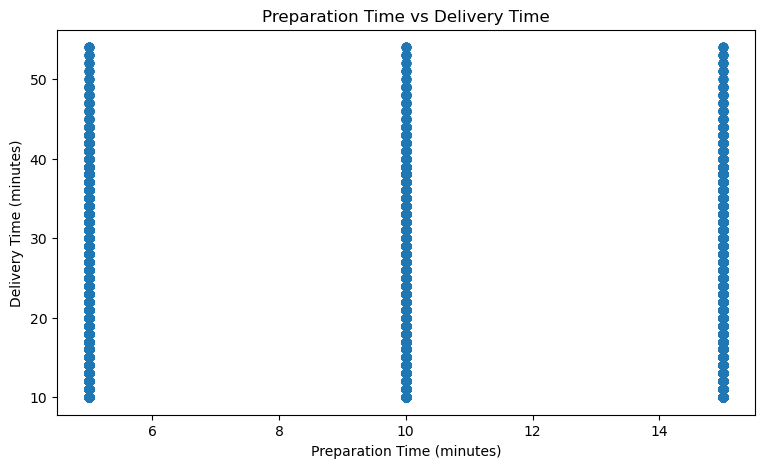

معامل الارتباط: -0.008

متوسط وقت التوصيل حسب وقت التجهيز:
Preparation_Time
5.0     26.35
10.0    26.37
15.0    26.16
Name: Time_taken(min), dtype: float64


In [69]:
# رسم العلاقة بين وقت تجهيز الطلب ووقت التوصيل
plt.figure(figsize=(9, 5))

plt.scatter(
    df_clean["Preparation_Time"],
    df_clean["Time_taken(min)"],
    alpha=0.3
)

# إضافة عنوان وتسميات المحاور
plt.title("Preparation Time vs Delivery Time")
plt.xlabel("Preparation Time (minutes)")
plt.ylabel("Delivery Time (minutes)")

# عرض الرسم
plt.show()

# حساب معامل الارتباط بين وقت التجهيز ووقت التوصيل
prep_correlation = df_clean[
    ["Preparation_Time", "Time_taken(min)"]
].corr().iloc[0, 1]

# حساب متوسط وقت التوصيل حسب وقت التجهيز
prep_analysis = df_clean.groupby(
    "Preparation_Time"
)["Time_taken(min)"].mean()

# عرض النتائج
print("معامل الارتباط:", round(prep_correlation, 3))
print("\nمتوسط وقت التوصيل حسب وقت التجهيز:")
print(prep_analysis.round(2))

**ملاحظة وتحليل النتائج:**

أظهرت النتائج أن العلاقة بين وقت تجهيز الطلب ووقت التوصيل شبه معدومة، حيث بلغ معامل الارتباط 0.008. كما كان متوسط وقت التوصيل متقاربًا عند أوقات التجهيز المختلفة؛ إذ بلغ 26.35 دقيقة عند التجهيز لمدة 5 دقائق، و26.37 دقيقة عند 10 دقائق، و26.16 دقيقة عند 15 دقيقة. وهذا يشير إلى أن وقت التجهيز وحده لا يرتبط بشكل واضح بوقت التوصيل في هذه البيانات.  

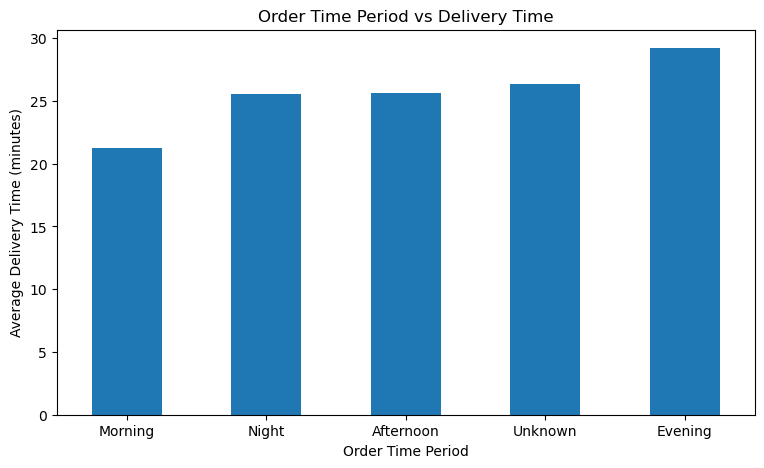

متوسط وقت التوصيل حسب الفترة:
Order_Time_Period
Morning      21.28
Night        25.53
Afternoon    25.64
Unknown      26.31
Evening      29.21
Name: Time_taken(min), dtype: float64


In [70]:
# رسم متوسط وقت التوصيل حسب الفترة الزمنية للطلب
period_analysis = df_clean.groupby(
    "Order_Time_Period"
)["Time_taken(min)"].mean().sort_values()

# إنشاء الرسم البياني
plt.figure(figsize=(9, 5))
period_analysis.plot(kind="bar")

# إضافة عنوان وتسميات
plt.title("Order Time Period vs Delivery Time")
plt.xlabel("Order Time Period")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=0)

# عرض الرسم
plt.show()

# عرض متوسط وقت التوصيل لكل فترة
print("متوسط وقت التوصيل حسب الفترة:")
print(period_analysis.round(2))

**ملاحظة وتحليل النتائج:**

أظهرت النتائج اختلاف متوسط وقت التوصيل حسب الفترة الزمنية للطلب. سجلت الفترة المسائية أعلى متوسط بلغ 29.21 دقيقة، بينما سجلت الفترة الصباحية أقل متوسط بلغ 21.28 دقيقة. وهذا يشير إلى أن وقت تقديم الطلب يرتبط باختلاف وقت التوصيل، وقد تكون هناك عوامل أخرى مثل الازدحام المروري والطقس تؤثر في هذه العلاقة.  

 اختيار الخصائص (Feature Selection)
هدفنا اختيار الأعمدة المفيدة للتنبؤ بوقت التوصيل، واستبعاد الأعمدة التي لا تضيف فائدة للنموذج، مثل أرقام التعريف التي تميز الطلبات فقط.

In [71]:
# عرض معلومات كل عمود لمساعدتنا في اختيار الخصائص
for col in df_clean.columns:

    print("\n------------------------------")
    print("اسم العمود:", col)

    # عرض نوع البيانات
    print("نوع البيانات:", df_clean[col].dtype)

    # عرض عدد القيم المختلفة
    print("عدد القيم المختلفة:", df_clean[col].nunique())

    # عرض عدد القيم المفقودة
    print("عدد القيم المفقودة:", df_clean[col].isna().sum())

    # عرض أمثلة من القيم
    print("أمثلة:", df_clean[col].dropna().unique()[:5])


------------------------------
اسم العمود: ID
نوع البيانات: object
عدد القيم المختلفة: 45593
عدد القيم المفقودة: 0
أمثلة: ['0x4607' '0xb379' '0x5d6d' '0x7a6a' '0x70a2']

------------------------------
اسم العمود: Delivery_person_ID
نوع البيانات: object
عدد القيم المختلفة: 1320
عدد القيم المفقودة: 0
أمثلة: ['INDORES13DEL02' 'BANGRES18DEL02' 'BANGRES19DEL01' 'COIMBRES13DEL02'
 'CHENRES12DEL01']

------------------------------
اسم العمود: Delivery_person_Age
نوع البيانات: float64
عدد القيم المختلفة: 22
عدد القيم المفقودة: 0
أمثلة: [37. 34. 23. 38. 32.]

------------------------------
اسم العمود: Delivery_person_Ratings
نوع البيانات: float64
عدد القيم المختلفة: 27
عدد القيم المفقودة: 0
أمثلة: [4.9 4.5 4.4 4.7 4.6]

------------------------------
اسم العمود: Restaurant_latitude
نوع البيانات: float64
عدد القيم المختلفة: 388
عدد القيم المفقودة: 4071
أمثلة: [22.745049 12.913041 12.914264 11.003669 12.972793]

------------------------------
اسم العمود: Restaurant_longitude
نوع البيانات: float6

### مراجعة الأعمدة التعريفية

من النتائج الظاهرة لدينا قراران مبدئيان:

- **ID:** يحتوي على 45,593 قيمة مختلفة، أي أن لكل طلب معرّفًا خاصًا به. لذلك سأستبعده؛ لأنه مجرد معرّف ولا يقدم معلومة تنبؤية مفيدة للنموذج.
- **Delivery_person_ID:** يحتوي على 1,320 معرّفًا مختلفًا للمندوبين. سأقيّمه قبل اتخاذ قرار الاستبعاد؛ لأنه قد يعكس اختلافًا بين المندوبين، لكنه يظل معرّفًا وليس خاصية مباشرة للطلب.  

In [72]:
# إنشاء ملخص لجميع الأعمدة
features_summary = pd.DataFrame({
    "Data_Type": df_clean.dtypes,
    "Unique_Values": df_clean.nunique(),
    "Missing_Values": df_clean.isna().sum()
})

# عرض الجدول كاملًا
print(features_summary.to_string())

                                     Data_Type  Unique_Values  Missing_Values
ID                                      object          45593               0
Delivery_person_ID                      object           1320               0
Delivery_person_Age                    float64             22               0
Delivery_person_Ratings                float64             27               0
Restaurant_latitude                    float64            388            4071
Restaurant_longitude                   float64            388            4071
Delivery_location_latitude             float64           4373               0
Delivery_location_longitude            float64           4373               0
Order_Date                      datetime64[ns]             44               0
Time_Orderd                             object            177               0
Time_Order_picked                       object            193               0
Weatherconditions                       object              7   

In [73]:
# حساب ارتباط الخصائص الرقمية بوقت التوصيل
numeric_features = df_clean.select_dtypes(include=["int64", "float64"])

correlation_with_target = numeric_features.corr()["Time_taken(min)"]

# ترتيب الخصائص حسب قوة الارتباط
correlation_with_target = correlation_with_target.drop(
    "Time_taken(min)"
).sort_values(ascending=False)

print("ارتباط الخصائص الرقمية بوقت التوصيل:")
print(correlation_with_target)

ارتباط الخصائص الرقمية بوقت التوصيل:
multiple_deliveries            0.378276
Distance_km                    0.321127
Delivery_person_Age            0.292861
Delivery_location_latitude     0.014243
Restaurant_latitude            0.013142
Delivery_location_longitude    0.007625
Restaurant_longitude           0.007036
Preparation_Time              -0.008478
Vehicle_condition             -0.234398
Delivery_person_Ratings       -0.332933
Name: Time_taken(min), dtype: float64


### تحليل ارتباط الخصائص الرقمية بالهدف

أظهرت النتائج أن أقوى ارتباط إيجابي مع وقت التوصيل كان لعدد الطلبات المتعددة `multiple_deliveries` بمعامل 0.378، ثم المسافة `Distance_km` بمعامل 0.321، ثم عمر المندوب بمعامل 0.293.

كما ظهر ارتباط سلبي مع تقييم المندوب بمعامل -0.333، ومع حالة المركبة بمعامل -0.234.

في المقابل، كان ارتباط وقت التجهيز ضعيفًا جدًا وبلغ -0.008، وكذلك الإحداثيات التي تراوحت معاملات ارتباطها بين 0.007 و0.014.

بناءً على ذلك، سأحتفظ مبدئيًا بالخصائص ذات الارتباط الملحوظ، وأراجع الخصائص ضعيفة الارتباط مع بقية الأدلة قبل اتخاذ قرار الاستبعاد النهائي.  

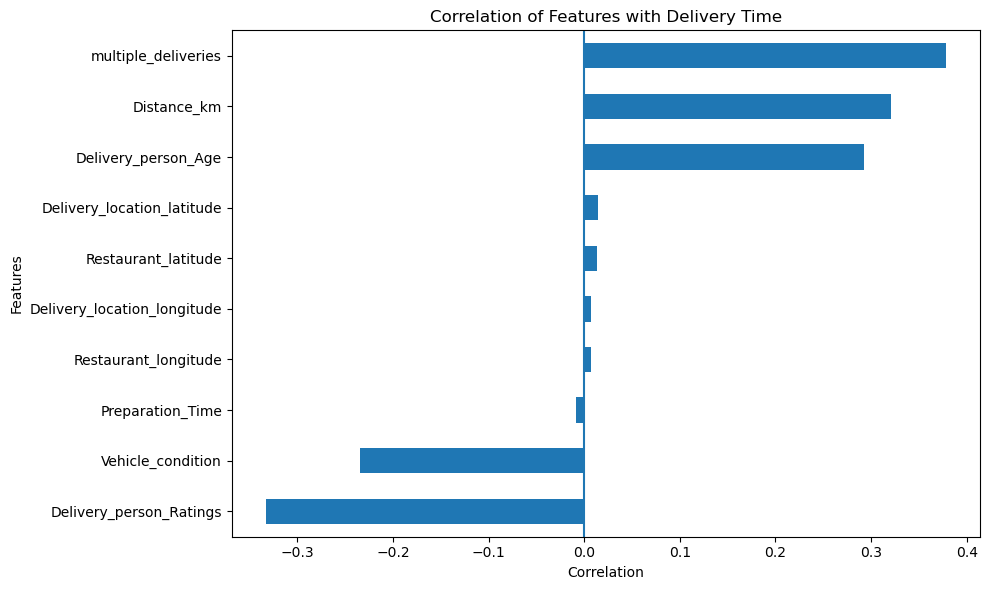

In [74]:
# رسم ارتباط الخصائص الرقمية بوقت التوصيل
plt.figure(figsize=(10, 6))

correlation_with_target.sort_values().plot(
    kind="barh"
)

plt.title("Correlation of Features with Delivery Time")
plt.xlabel("Correlation")
plt.ylabel("Features")
plt.axvline(0)
plt.tight_layout()
plt.show()

### مراجعة الخصائص المشتقة والإحداثيات

- `Distance_km`: سأحتفظ بها لأنها تمثل المسافة بين المطعم وموقع التوصيل، وبلغ ارتباطها بوقت التوصيل 0.321.
- `Restaurant_latitude` و`Restaurant_longitude`: سأستبعدهما مبدئيًا بعد إنشاء خاصية المسافة؛ لأنهما استُخدما في حسابها، ويحتوي كل منهما على 4,071 قيمة مفقودة.
- `Delivery_location_latitude` و`Delivery_location_longitude`: سأراجع الحاجة إليهما؛ لأن ارتباطهما الخطي بالهدف ضعيف جدًا.
- `Preparation_Time`: سأحتفظ بها مؤقتًا للمقارنة، رغم أن ارتباطها الخطي ضعيف وبلغ -0.008.
- `Distance_Group`: سأستبعدها من ملف النموذج؛ لأنها تقسيم للمسافة الموجودة أصلًا في `Distance_km`، واستخدمتها لتحليل النتائج.
- `Restaurant_coordinates_missing`: سأحتفظ بها لأنها توضح وجود إحداثيات مطعم مفقودة، وعدد الحالات التي تحمل القيمة 1 هو 4,071.  

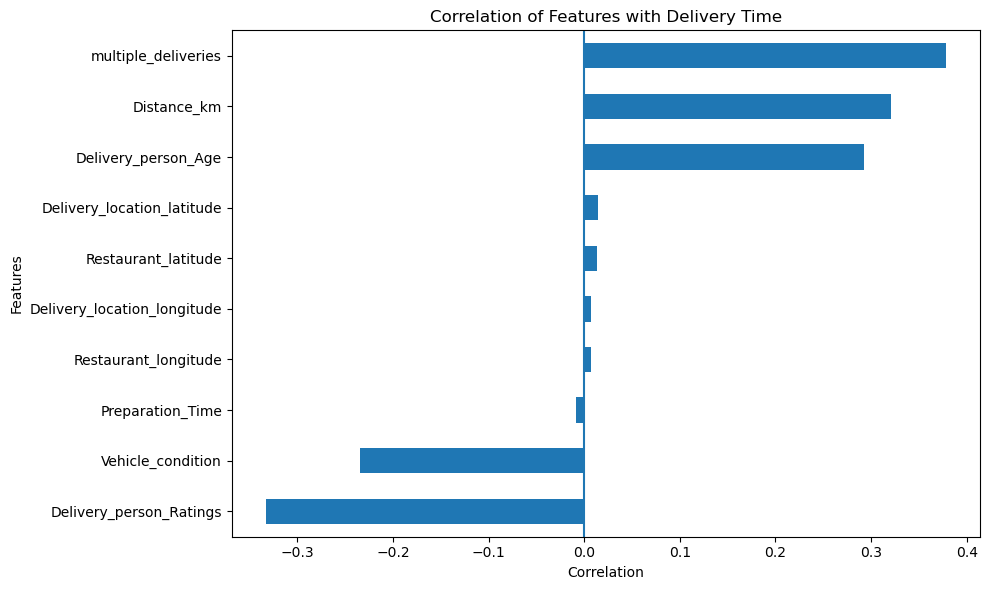

In [75]:
## رسم ارتباط الخصائص الرقمية بوقت التوصيل
plt.figure(figsize=(10, 6))

correlation_with_target.sort_values().plot(
    kind="barh"
)

plt.title("Correlation of Features with Delivery Time")
plt.xlabel("Correlation")
plt.ylabel("Features")
plt.axvline(0)
plt.tight_layout()
plt.show()

### مراجعة أعمدة الوقت والتاريخ

- `Order_Date`: سأحتفظ به مؤقتًا لأنه يحتوي على 44 تاريخًا مختلفًا، وقد يساعد في اكتشاف التغيرات المرتبطة بأيام الطلب.
- `Time_Orderd`: سأستبعده من الخصائص النهائية بعد إنشاء `Order_Time_Period`؛ لأن الخاصية الجديدة تمثل الفترة الزمنية للطلب بصورة أبسط، كما يحتوي العمود الأصلي على 1,731 قيمة غير معروفة.
- `Time_Order_picked`: سأستبعده من الخصائص النهائية بعد إنشاء `Preparation_Time`؛ لأن مدة التجهيز أصبحت ممثلة في خاصية رقمية جديدة.
- `Order_Time_Period`: سأحتفظ به لأنه يصنف وقت الطلب إلى فترات، وقد أظهرت النتائج اختلاف متوسط وقت التوصيل بين الفترات.  

In [76]:
# عرض توزيع القيم في الأعمدة التصنيفية
categorical_columns = [
    "Weatherconditions",
    "Road_traffic_density",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City"
]

for col in categorical_columns:
    print("\nالعمود:", col)
    print(df_clean[col].value_counts())


العمود: Weatherconditions
Weatherconditions
Fog           7654
Stormy        7586
Cloudy        7536
Sandstorms    7495
Windy         7422
Sunny         7284
Unknown        616
Name: count, dtype: int64

العمود: Road_traffic_density
Road_traffic_density
Low        15477
Jam        14143
Medium     10947
High        4425
Unknown      601
Name: count, dtype: int64

العمود: Type_of_order
Type_of_order
Snack     11533
Meal      11458
Drinks    11322
Buffet    11280
Name: count, dtype: int64

العمود: Type_of_vehicle
Type_of_vehicle
motorcycle          26435
scooter             15276
electric_scooter     3814
bicycle                68
Name: count, dtype: int64

العمود: Festival
Festival
No         44469
Yes          896
Unknown      228
Name: count, dtype: int64

العمود: City
City
Metropolitian    34093
Urban            10136
Unknown           1200
Semi-Urban         164
Name: count, dtype: int64


### مراجعة الأعمدة التصنيفية

- `Weatherconditions`: سأحتفظ به؛ لأنه يحتوي على 6 حالات جوية مختلفة بالإضافة إلى 616 قيمة Unknown، وقد تؤثر حالة الطقس في وقت التوصيل.
- `Road_traffic_density`: سأحتفظ به؛ لأنه يمثل كثافة الازدحام المروري، وقد أظهرت نتائج التحليل السابقة اختلاف متوسط وقت التوصيل بين مستويات الازدحام.
- `Type_of_order`: سأحتفظ به؛ لأنه يوضح نوع الطلب، مثل الوجبات والمشروبات والوجبات الخفيفة.
- `Type_of_vehicle`: سأحتفظ به؛ لأنه يوضح نوع وسيلة التوصيل، وقد يكون له تأثير في وقت الوصول.
- `Festival`: سأحتفظ به؛ لأنه يوضح ما إذا كان الطلب خلال فترة مهرجان، وقد يؤثر ذلك في ظروف التوصيل.
- `City`: سأحتفظ به لأنه يمثل نوع المنطقة، مع الانتباه إلى أن فئة Semi-Urban تحتوي على 164 سجلًا فقط، وهذا لا يكفي وحده لاستبعادها.

سأحتفظ بهذه الخصائص مبدئيًا لأنها تمثل معلومات مرتبطة بعملية التوصيل، ولا يوجد دليل كافٍ على أنها غير مفيدة.   

In [77]:
# عرض توزيع الخصائص الرقمية والتصنيفية ذات القيم المحدودة
columns_to_check = [
    "Vehicle_condition",
    "multiple_deliveries",
    "Festival",
    "City"
]

for col in columns_to_check:
    print("\nالعمود:", col)
    print(df_clean[col].value_counts())


العمود: Vehicle_condition
Vehicle_condition
2    15034
1    15030
0    15009
3      520
Name: count, dtype: int64

العمود: multiple_deliveries
multiple_deliveries
1.0    29152
0.0    14095
2.0     1985
3.0      361
Name: count, dtype: int64

العمود: Festival
Festival
No         44469
Yes          896
Unknown      228
Name: count, dtype: int64

العمود: City
City
Metropolitian    34093
Urban            10136
Unknown           1200
Semi-Urban         164
Name: count, dtype: int64


### مراجعة الخصائص الرقمية ذات القيم المحدودة

- `Vehicle_condition`: سأحتفظ به؛ لأنه يوضح حالة المركبة، وتتوزع القيم بين 0 و3. حتى الفئة الأقل تكرارًا، وهي 3، تحتوي على 520 سجلًا، لذلك لا يوجد سبب كافٍ لاستبعادها.
- `multiple_deliveries`: سأحتفظ به؛ لأنه يمثل عدد الطلبات التي يتعامل معها المندوب، وقد بلغ ارتباطه بوقت التوصيل 0.378، وهو أعلى ارتباط إيجابي بين الخصائص الرقمية التي فحصناها.  

In [78]:
# عرض جميع الأعمدة الموجودة حاليًا
print("عدد الأعمدة:", len(df_clean.columns))

for col in df_clean.columns:
    print(col)

عدد الأعمدة: 25
ID
Delivery_person_ID
Delivery_person_Age
Delivery_person_Ratings
Restaurant_latitude
Restaurant_longitude
Delivery_location_latitude
Delivery_location_longitude
Order_Date
Time_Orderd
Time_Order_picked
Weatherconditions
Road_traffic_density
Vehicle_condition
Type_of_order
Type_of_vehicle
multiple_deliveries
Festival
City
Time_taken(min)
Restaurant_coordinates_missing
Distance_km
Preparation_Time
Order_Time_Period
Distance_Group


In [79]:
# إنشاء نسخة من البيانات النظيفة والخصائص الجديدة
model_ready = df_clean.copy()

# استخراج يوم الأسبوع من تاريخ الطلب
# 0 = الاثنين، و6 = الأحد
model_ready["Order_DayOfWeek"] = model_ready["Order_Date"].dt.dayofweek

# تحديد الأعمدة التي سنحتفظ بها للنموذج
selected_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Weatherconditions",
    "Road_traffic_density",
    "Vehicle_condition",
    "Type_of_order",
    "Type_of_vehicle",
    "multiple_deliveries",
    "Festival",
    "City",
    "Restaurant_coordinates_missing",
    "Distance_km",
    "Preparation_Time",
    "Order_Time_Period",
    "Order_DayOfWeek",
    "Time_taken(min)"
]

# الاحتفاظ بالأعمدة المختارة فقط
model_ready = model_ready[selected_columns].copy()

# عرض حجم البيانات والأعمدة والقيم المفقودة
print("حجم بيانات النموذج:", model_ready.shape)
print("\nالأعمدة المختارة:")
print(model_ready.columns.tolist())
print("\nالقيم المفقودة:")
print(model_ready.isnull().sum())

حجم بيانات النموذج: (45593, 16)

الأعمدة المختارة:
['Delivery_person_Age', 'Delivery_person_Ratings', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Restaurant_coordinates_missing', 'Distance_km', 'Preparation_Time', 'Order_Time_Period', 'Order_DayOfWeek', 'Time_taken(min)']

القيم المفقودة:
Delivery_person_Age                  0
Delivery_person_Ratings              0
Weatherconditions                    0
Road_traffic_density                 0
Vehicle_condition                    0
Type_of_order                        0
Type_of_vehicle                      0
multiple_deliveries                  0
Festival                             0
City                                 0
Restaurant_coordinates_missing       0
Distance_km                       4071
Preparation_Time                  1731
Order_Time_Period                    0
Order_DayOfWeek                      0
Time_taken(min)        

In [80]:
# حفظ البيانات المختارة في ملف CSV
model_ready.to_csv("data/model_ready.csv", index=False)

# طباعة رسالة تؤكد الحفظ
print("تم حفظ ملف بيانات النموذج بنجاح")

تم حفظ ملف بيانات النموذج بنجاح


In [81]:
# قراءة ملف البيانات المجهز للنموذج
model_check = pd.read_csv("data/model_ready.csv")

# عرض حجم الملف
print("حجم الملف:", model_check.shape)

# عرض أول خمسة صفوف
display(model_check.head())

# التحقق من أسماء الأعمدة
print("\nأسماء الأعمدة:")
print(model_check.columns.tolist())

حجم الملف: (45593, 16)


,Delivery_person_Age,Delivery_person_Ratings,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Restaurant_coordinates_missing,Distance_km,Preparation_Time,Order_Time_Period,Order_DayOfWeek,Time_taken(min)
0,37.0,4.9,Sunny,High,2,Snack,motorcycle,0.0,No,Urban,0,3.025149,15.0,Morning,5,24
1,34.0,4.5,Stormy,Jam,2,Snack,scooter,1.0,No,Metropolitian,0,20.183530,5.0,Evening,4,33
2,23.0,4.4,Sandstorms,Low,0,Drinks,motorcycle,1.0,No,Urban,0,1.552758,15.0,Morning,5,26
3,38.0,4.7,Sunny,Medium,0,Buffet,motorcycle,1.0,No,Metropolitian,0,7.790401,10.0,Evening,1,21
4,32.0,4.6,Cloudy,High,1,Snack,scooter,1.0,No,Metropolitian,0,6.210138,15.0,Afternoon,5,30



أسماء الأعمدة:
['Delivery_person_Age', 'Delivery_person_Ratings', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Restaurant_coordinates_missing', 'Distance_km', 'Preparation_Time', 'Order_Time_Period', 'Order_DayOfWeek', 'Time_taken(min)']


In [82]:
print(model_check.columns.tolist())
print("\nعدد الأعمدة:", len(model_check.columns))
print("\nالقيم المفقودة:")
print(model_check.isnull().sum())

['Delivery_person_Age', 'Delivery_person_Ratings', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Restaurant_coordinates_missing', 'Distance_km', 'Preparation_Time', 'Order_Time_Period', 'Order_DayOfWeek', 'Time_taken(min)']

عدد الأعمدة: 16

القيم المفقودة:
Delivery_person_Age                  0
Delivery_person_Ratings              0
Weatherconditions                    0
Road_traffic_density                 0
Vehicle_condition                    0
Type_of_order                        0
Type_of_vehicle                      0
multiple_deliveries                  0
Festival                             0
City                                 0
Restaurant_coordinates_missing       0
Distance_km                       4071
Preparation_Time                  1731
Order_Time_Period                    0
Order_DayOfWeek                      0
Time_taken(min)                      0
dtype: int64


In [85]:

# تحليل متوسط وقت التوصيل حسب نوع المركبة

# تجميع الطلبات حسب نوع المركبة
# حتى نتمكن من مقارنة وقت التوصيل بين أنواع المركبات المختلفة
vehicle_analysis = (
    model_check.groupby("Type_of_vehicle")["Time_taken(min)"]

    # حساب متوسط وقت التوصيل (mean)
    # وحساب عدد الطلبات (count) لكل نوع من المركبات
    .agg(["mean", "count"])
)

# طباعة عنوان يوضح محتوى النتائج
print("\nمتوسط وقت التوصيل حسب نوع المركبة:")

# عرض النتائج بعد تقريب الأرقام إلى منزلتين عشريتين
print(vehicle_analysis.round(2))



متوسط وقت التوصيل حسب نوع المركبة:
                   mean  count
Type_of_vehicle               
bicycle           26.43     68
electric_scooter  24.47   3814
motorcycle        27.61  26435
scooter           24.48  15276


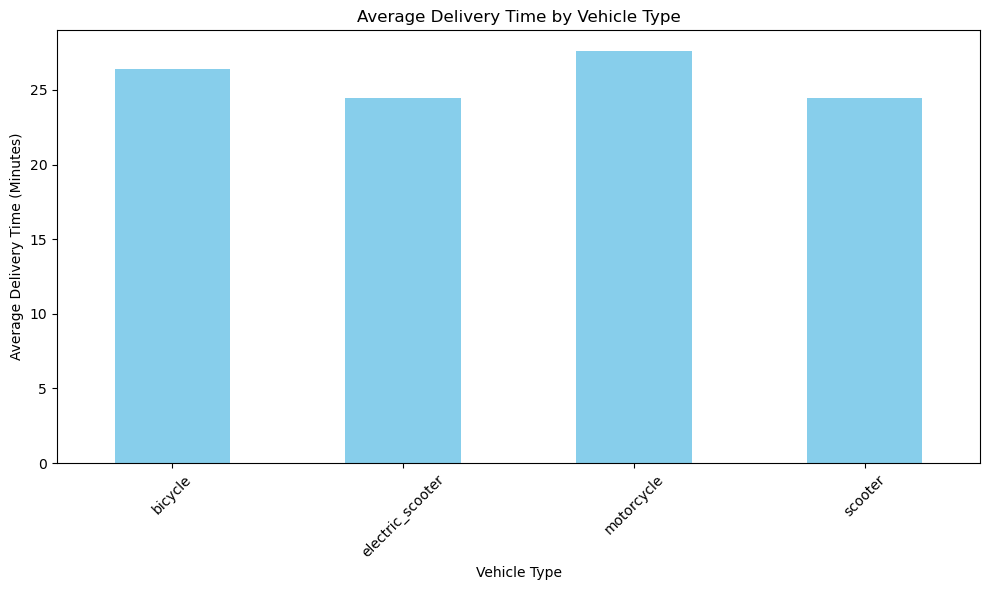

In [86]:

# رسم متوسط وقت التوصيل حسب نوع المركبة

# إنشاء مساحة للرسم وتحديد حجم الشكل
plt.figure(figsize=(10, 6))

# رسم متوسط وقت التوصيل لكل نوع من المركبات
vehicle_analysis["mean"].plot(
    kind="bar",
    color="skyblue"
)

# إضافة عنوان واضح للرسم
plt.title("Average Delivery Time by Vehicle Type")

# تسمية المحور الأفقي
plt.xlabel("Vehicle Type")

# تسمية المحور الرأسي
plt.ylabel("Average Delivery Time (Minutes)")

# تدوير أسماء أنواع المركبات لتسهيل قراءتها
plt.xticks(rotation=45)

# ضبط المسافات حتى لا تتداخل عناصر الرسم
plt.tight_layout()

# عرض الرسم البياني
plt.show()


: يساعدنا على مقارنة متوسط وقت التوصيل بين أنواع المركبات بصريًا، وتحديد النوع الذي سجل أعلى وأقل متوسط.   

In [87]:

# تحليل متوسط وقت التوصيل حسب حالة الطقس

# تجميع الطلبات حسب حالة الطقس واختيار عمود وقت التوصيل
weather_analysis = (
    model_check.groupby("Weatherconditions")["Time_taken(min)"]

    # حساب متوسط وقت التوصيل وعدد الطلبات لكل حالة جوية
    .agg(["mean", "count"])

    # ترتيب النتائج من أعلى متوسط إلى أقل متوسط
    .sort_values("mean", ascending=False)
)

# طباعة عنوان النتائج
print("متوسط وقت التوصيل حسب حالة الطقس:")

# عرض النتائج بعد تقريب الأرقام إلى منزلتين عشريتين
print(weather_analysis.round(2))


متوسط وقت التوصيل حسب حالة الطقس:
                    mean  count
Weatherconditions              
Cloudy             28.92   7536
Fog                28.92   7654
Unknown            26.55    616
Windy              26.12   7422
Sandstorms         25.88   7495
Stormy             25.87   7586
Sunny              21.86   7284


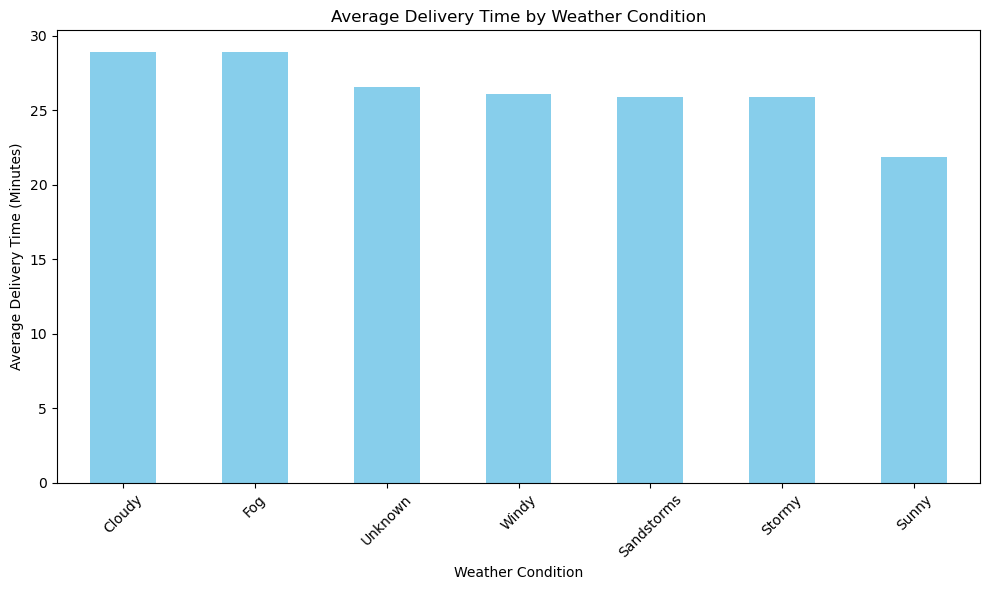

In [88]:

# رسم متوسط وقت التوصيل حسب حالة الطقس

# تحديد حجم الرسم البياني ليكون واضحًا
plt.figure(figsize=(10, 6))

# رسم متوسط وقت التوصيل لكل حالة جوية
weather_analysis["mean"].plot(
    kind="bar",
    color="skyblue"
)

# إضافة عنوان يوضح محتوى الرسم
plt.title("Average Delivery Time by Weather Condition")

# تسمية المحور الأفقي بحالة الطقس
plt.xlabel("Weather Condition")

# تسمية المحور الرأسي بمتوسط وقت التوصيل بالدقائق
plt.ylabel("Average Delivery Time (Minutes)")

# تدوير أسماء حالات الطقس لتسهيل قراءتها
plt.xticks(rotation=45)

# ضبط المسافات بين عناصر الرسم
plt.tight_layout()

# عرض الرسم البياني
plt.show()


In [89]:

# تحليل متوسط وقت التوصيل حسب كثافة المرور

# تجميع الطلبات حسب مستوى كثافة المرور
# واختيار عمود وقت التوصيل بالدقائق
traffic_analysis = (
    model_check.groupby("Road_traffic_density")["Time_taken(min)"]

    # حساب متوسط وقت التوصيل وعدد الطلبات لكل مستوى مرور
    .agg(["mean", "count"])

    # ترتيب النتائج من أعلى متوسط إلى أقل متوسط
    .sort_values("mean", ascending=False)
)

# طباعة عنوان النتائج
print("متوسط وقت التوصيل حسب كثافة المرور:")

# عرض النتائج بعد تقريب الأرقام إلى منزلتين عشريتين
print(traffic_analysis.round(2))


متوسط وقت التوصيل حسب كثافة المرور:
                       mean  count
Road_traffic_density              
Jam                   31.18  14143
High                  27.24   4425
Medium                26.70  10947
Unknown               26.54    601
Low                   21.27  15477


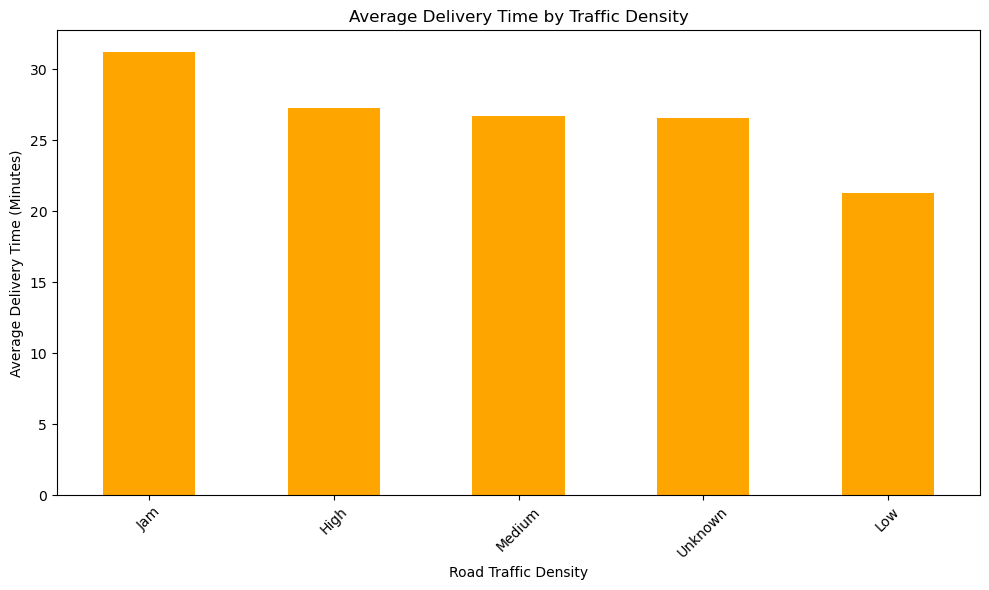

In [90]:

# رسم متوسط وقت التوصيل حسب كثافة المرور

# تحديد حجم الرسم البياني
plt.figure(figsize=(10, 6))

# رسم متوسط وقت التوصيل لكل مستوى من مستويات المرور
traffic_analysis["mean"].plot(
    kind="bar",
    color="orange"
)

# إضافة عنوان واضح للرسم
plt.title("Average Delivery Time by Traffic Density")

# تسمية المحور الأفقي
plt.xlabel("Road Traffic Density")

# تسمية المحور الرأسي
plt.ylabel("Average Delivery Time (Minutes)")

# تدوير أسماء مستويات المرور لتسهيل قراءتها
plt.xticks(rotation=45)

# ضبط تنسيق الرسم
plt.tight_layout()

# عرض الرسم البياني
plt.show()


In [91]:
# تحليل متوسط وقت التوصيل حسب المسافة

# تقسيم المسافات إلى خمس مجموعات متساوية في النطاق
distance_groups = pd.cut(
    model_check["Distance_km"],
    bins=5
)

# تجميع الطلبات حسب مجموعة المسافة
distance_analysis = (
    model_check.groupby(distance_groups, observed=True)["Time_taken(min)"]

    # حساب متوسط وقت التوصيل وعدد الطلبات في كل مجموعة
    .agg(["mean", "count"])

    # ترتيب النتائج من أعلى متوسط إلى أقل متوسط
    .sort_values("mean", ascending=False)
)

# طباعة عنوان النتائج
print("متوسط وقت التوصيل حسب المسافة:")

# عرض النتائج بعد تقريب الأرقام إلى منزلتين عشريتين
print(distance_analysis.round(2))

متوسط وقت التوصيل حسب المسافة:
                   mean  count
Distance_km                   
(13.168, 17.069]  29.87   6258
(17.069, 20.969]  29.82   5421
(9.267, 13.168]   29.00   8673
(5.366, 9.267]    24.48   9983
(1.446, 5.366]    22.18  11187


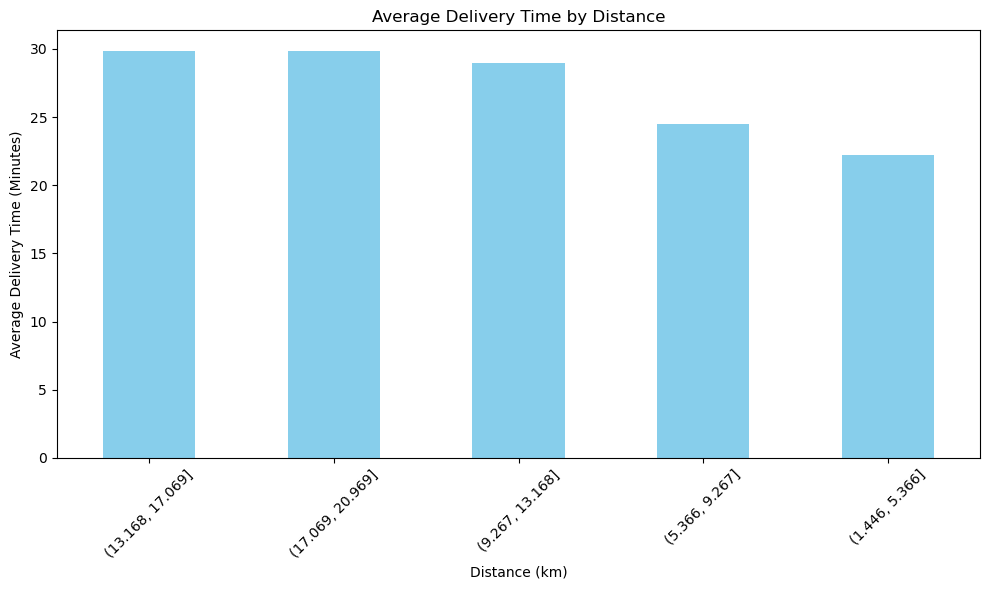

In [92]:
# رسم متوسط وقت التوصيل حسب المسافة

# تحديد حجم الرسم البياني
plt.figure(figsize=(10, 6))

# رسم متوسط وقت التوصيل لكل مجموعة من المسافات
distance_analysis["mean"].plot(
    kind="bar",
    color="skyblue"
)

# إضافة عنوان واضح للرسم
plt.title("Average Delivery Time by Distance")

# تسمية المحور الأفقي
plt.xlabel("Distance (km)")

# تسمية المحور الرأسي
plt.ylabel("Average Delivery Time (Minutes)")

# تدوير أسماء فئات المسافة لتسهيل قراءتها
plt.xticks(rotation=45)

# ضبط المسافات حتى لا تتداخل عناصر الرسم
plt.tight_layout()

# عرض الرسم البياني
plt.show()

In [93]:
# تحليل متوسط وقت التوصيل حسب فترة الطلب

# تجميع البيانات حسب الفترة الزمنية للطلب
period_analysis = (
    model_check.groupby("Order_Time_Period")["Time_taken(min)"]

    # حساب متوسط وقت التوصيل وعدد الطلبات
    .agg(["mean", "count"])

    # ترتيب النتائج من أعلى متوسط إلى أقل متوسط
    .sort_values("mean", ascending=False)
)

# طباعة عنوان النتائج
print("متوسط وقت التوصيل حسب فترة الطلب:")

# عرض النتائج بعد تقريب الأرقام إلى منزلتين عشريتين
print(period_analysis.round(2))

متوسط وقت التوصيل حسب فترة الطلب:
                    mean  count
Order_Time_Period              
Evening            29.21  17892
Unknown            26.31   1731
Afternoon          25.64   4049
Night              25.53  14203
Morning            21.28   7718


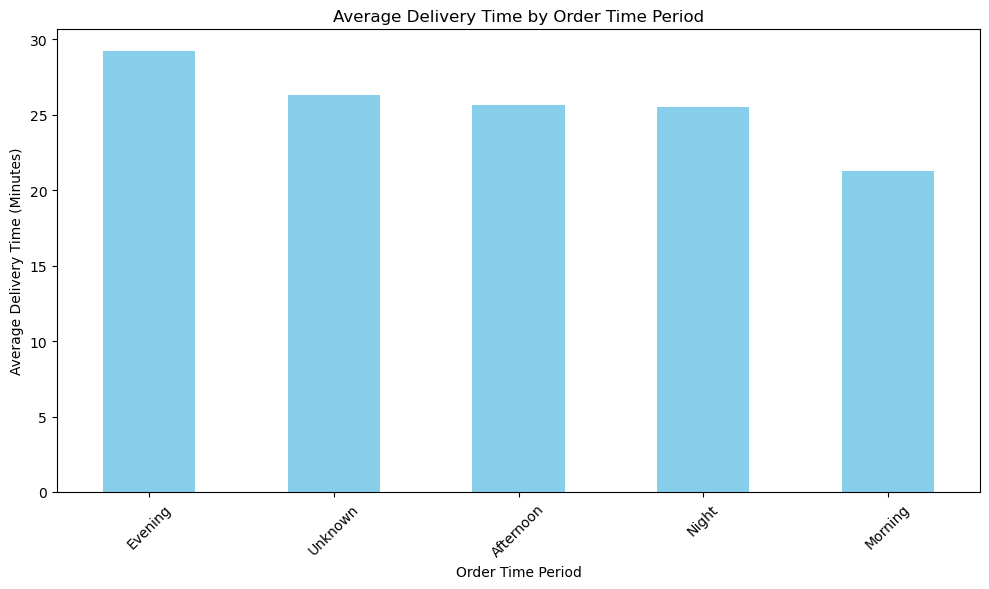

In [94]:
# رسم متوسط وقت التوصيل حسب فترة الطلب

# تحديد حجم الرسم البياني
plt.figure(figsize=(10, 6))

# رسم متوسط وقت التوصيل لكل فترة
period_analysis["mean"].plot(
    kind="bar",
    color="skyblue"
)

# إضافة عنوان واضح للرسم
plt.title("Average Delivery Time by Order Time Period")

# تسمية المحور الأفقي
plt.xlabel("Order Time Period")

# تسمية المحور الرأسي
plt.ylabel("Average Delivery Time (Minutes)")

# تدوير أسماء الفترات لتسهيل قراءتها
plt.xticks(rotation=45)

# ضبط المسافات بين عناصر الرسم
plt.tight_layout()

# عرض الرسم البياني
plt.show()

## الاكتشافات

### الاكتشاف الأول: نوع المركبة
أظهرت البيانات أن متوسط وقت التوصيل باستخدام الدراجة النارية بلغ 27.61 دقيقة، مقارنة بـ24.47 دقيقة باستخدام السكوتر الكهربائي، بفارق 3.14 دقائق.

**ماذا يعني للعميل؟** يمكن مراعاة اختلاف متوسط وقت التوصيل بين أنواع المركبات عند توزيع الطلبات وتقدير أوقات الوصول.

### الاكتشاف الثاني: حالة الطقس
بلغ متوسط وقت التوصيل في الطقس الغائم والضباب 28.92 دقيقة، مقارنة بـ21.86 دقيقة في الطقس المشمس، بفارق 7.06 دقائق.

**ماذا يعني للعميل؟** ينبغي مراعاة حالة الطقس عند تقدير وقت وصول الطلبات وتخطيط توزيع المندوبين.

### الاكتشاف الثالث: كثافة المرور
بلغ متوسط وقت التوصيل في الازدحام الشديد 31.18 دقيقة، مقارنة بـ21.27 دقيقة في المرور المنخفض، بفارق 9.91 دقائق.

**ماذا يعني للعميل؟** ينبغي أخذ كثافة المرور في الاعتبار عند تقدير أوقات الوصول، خصوصًا في أوقات الازدحام الشديد.

### الاكتشاف الرابع: المسافة
بلغ متوسط وقت التوصيل للمسافات من 13.168 إلى 17.069 كم نحو 29.87 دقيقة، مقارنة بـ22.18 دقيقة للمسافات من 1.446 إلى 5.366 كم، بفارق 7.69 دقائق.

**ماذا يعني للعميل؟** ينبغي مراعاة مسافة التوصيل عند تقدير الوقت المتوقع لوصول الطلب.

### الاكتشاف الخامس: فترة الطلب
بلغ متوسط وقت التوصيل في فترة المساء 29.21 دقيقة، مقارنة بـ21.28 دقيقة في فترة الصباح، بفارق 7.93 دقائق.

**ماذا يعني للعميل؟** ينبغي مراعاة ارتفاع متوسط وقت التوصيل في المساء عند تحديد الوقت المتوقع لوصول الطلبات.  

## 9. التوصيات

### التوصية الأولى: تحسين تخطيط أوقات التوصيل
بناءً على الاكتشاف الثالث، الذي أظهر أن متوسط وقت التوصيل في الازدحام الشديد بلغ 31.18 دقيقة مقابل 21.27 دقيقة في المرور المنخفض، أوصي بمراعاة كثافة المرور عند توزيع الطلبات وتقدير أوقات الوصول.

### التوصية الثانية: مراعاة ظروف الطقس
بناءً على الاكتشاف الثاني، الذي أظهر ارتفاع متوسط وقت التوصيل في الطقس الغائم والضباب إلى 28.92 دقيقة مقابل 21.86 دقيقة في الطقس المشمس، أوصي بتعديل تقديرات وقت الوصول بما يتناسب مع ظروف الطقس.

### التوصية الثالثة: مراعاة فترة الطلب
بناءً على الاكتشاف الخامس، الذي أظهر أن متوسط وقت التوصيل في المساء بلغ 29.21 دقيقة مقابل 21.28 دقيقة في الصباح، أوصي بتوفير تخطيط مناسب للمندوبين خلال فترة المساء.

### حدود البيانات
لا تستطيع البيانات إثبات أن الطقس أو الازدحام أو فترة الطلب هي الأسباب المباشرة لزيادة وقت التوصيل؛ فهي توضح ارتباطات بين هذه العوامل ووقت التوصيل، والارتباط لا يعني السببية.  

In [95]:
# إنشاء مجلد data إذا لم يكن موجودًا
import os
os.makedirs("data", exist_ok=True)

# حفظ البيانات التي أجرينا عليها التحليلات
model_check.to_csv("data/clean.csv", index=False)

# التأكد من حفظ الملف
print("تم حفظ البيانات بنجاح")
print("حجم البيانات:", model_check.shape)
print("أسماء الأعمدة:", model_check.columns.tolist())

تم حفظ البيانات بنجاح
حجم البيانات: (45593, 16)
أسماء الأعمدة: ['Delivery_person_Age', 'Delivery_person_Ratings', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Restaurant_coordinates_missing', 'Distance_km', 'Preparation_Time', 'Order_Time_Period', 'Order_DayOfWeek', 'Time_taken(min)']


### الإجابة عن سؤال العميل

**ما الذي يؤخر الطلب؟**

من خلال تحليل 45,593 طلبًا، ظهرت عدة عوامل مرتبطة باختلاف وقت التوصيل:

- **الزحمة:** سجل الازدحام الشديد (Jam) أعلى متوسط، وهو 31.18 دقيقة، مقارنة بالمرور المنخفض (Low) الذي بلغ 21.27 دقيقة، بفارق 9.91 دقيقة.
- **الطقس:** سجل الطقس الغائم والضباب أعلى متوسط، وهو 28.92 دقيقة، مقارنة بالطقس المشمس الذي بلغ 21.86 دقيقة، بفارق 7.06 دقائق.
- **المسافة:** سجلت فئة المسافة من 13.168 إلى 17.069 كم متوسطًا قدره 29.87 دقيقة، مقارنة بفئة 1.446 إلى 5.366 كم التي بلغ متوسطها 22.18 دقيقة.
- **فترة الطلب:** سجل المساء متوسطًا قدره 29.21 دقيقة، مقارنة بالصباح الذي بلغ 21.28 دقيقة.
- **نوع المركبة:** سجلت الدراجات النارية متوسطًا قدره 27.61 دقيقة، مقارنة بالدراجات الكهربائية التي بلغ متوسطها 24.47 دقيقة.

بناءً على النتائج، يظهر أن كثافة المرور كانت صاحبة أكبر فرق في متوسط وقت التوصيل بين الفئات التي حللناها، تليها فترة الطلب والطقس والمسافة. ولا يمكن الجزم بأن هذه العوامل تسبب التأخير بشكل مباشر، كما أن التحليل لا يثبت أن المندوب هو السبب.

**كيف نعطي العميل وقتًا متوقعًا أدق؟**

يمكن تطوير نموذج تعلم آلي يستخدم بيانات الطلب، مثل المسافة، وكثافة المرور، والطقس، ونوع المركبة، وفترة الطلب، ووقت التحضير، للتنبؤ بوقت التوصيل المتوقع. ثم نعرض للعميل وقتًا تقديريًا يعتمد على ظروف طلبه بدلًا من إعطاء جميع العملاء الوقت نفسه.   